# NIDS  CRISP-DM sur un échantillon stratifié de 3 millions de flux

**Objectif métier conservé :** détecter les attaques (`Label`: 0 = bénin, 1 = attaque), en maximisant le rappel sous une contrainte opérationnelle provisoire de **FPR ≤ 1 %**. `Attack` sert à préserver les classes lors de l’échantillonnage, de la séparation et à détailler les résultats ; cette colonne est exclue des variables prédictives pour éviter la fuite de cible.

## Protocole et portée

Le prélèvement est proportionnel aux effectifs de chaque combinaison (`Label`, `Attack`), avec allocation des arrondis par la méthode des plus grands restes. Il conserve donc les parts de `Label` et de chaque classe `Attack` à l’arrondi près, sans sur-échantillonner les attaques rares. La sélection est aléatoire sans remise dans chaque strate et reproductible avec une graine fixe.

Après l’exploration et le nettoyage, les données sont séparées en train/test de façon stratifiée sur les mêmes combinaisons. Une validation croisée stratifiée à 5 plis est réalisée dans le train. Le seuil opérationnel est calibré sur les prédictions hors pli du train et évalué une seule fois sur le test tenu à l’écart.

## 1. CRISP-DM : Business Understanding

Un NIDS doit détecter les flux malveillants sans noyer les analystes sous les fausses alertes. L’objectif est de produire un détecteur binaire et de mesurer son rappel sous FPR ≤ 1 %. Les métriques rapportées incluent PR-AUC, rappel, précision, F1, MCC, balanced accuracy, FPR et matrice de confusion. Le seuil est choisi sans consulter le test.

La contrainte de 1 % est reprise du notebook d’origine ; elle reste une hypothèse à faire valider par l’équipe opérationnelle.

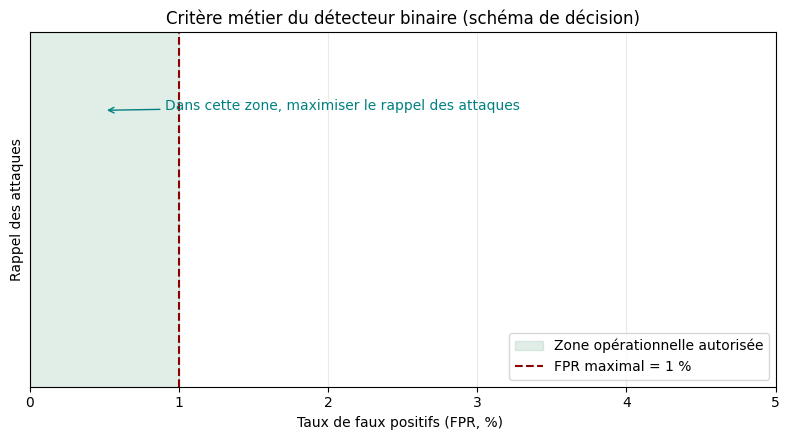

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axvspan(0, 1, color="seagreen", alpha=0.14, label="Zone opérationnelle autorisée")
ax.axvline(1, color="darkred", linestyle="--", label="FPR maximal = 1 %")
ax.annotate("Dans cette zone, maximiser le rappel des attaques", xy=(0.5, 0.78),
            xytext=(2.1, 0.78), arrowprops={"arrowstyle": "->", "color": "teal"},
            color="teal", ha="center")
ax.set(xlim=(0, 5), ylim=(0, 1), xlabel="Taux de faux positifs (FPR, %) ",
       ylabel="Rappel des attaques", title="Critère métier du détecteur binaire (schéma de décision)")
ax.set_yticks([])
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 2. Environnement et chemins

In [6]:
from pathlib import Path
from collections import Counter
import gzip
import gc
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

SOURCE_NAME = "NF-ToN-IoT-v3.csv"
SAMPLE_NAME = "NF-ToN-IoT-v3_sample_3m.csv.gz"
MANIFEST_NAME = "NF-ToN-IoT-v3_sample_3m_manifest.json"
SAMPLE_SIZE = 3_000_000
SAMPLE_SEED = 42
CSV_CHUNK_ROWS = 200_000
MAX_FPR = 0.01
RANDOM_STATE = 42

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / SOURCE_NAME).is_file():
    PROJECT_DIR = next(
        (p for p in [PROJECT_DIR, *PROJECT_DIR.parents] if (p / SOURCE_NAME).is_file()),
        PROJECT_DIR
    )
SOURCE_PATH = PROJECT_DIR / SOURCE_NAME
SAMPLE_PATH = PROJECT_DIR / "data" / SAMPLE_NAME
MANIFEST_PATH = PROJECT_DIR / "data" / MANIFEST_NAME
if not SOURCE_PATH.is_file():
    raise FileNotFoundError(f"Dataset initial introuvable : {SOURCE_PATH}")

print("Projet :", PROJECT_DIR)
print("Dataset initial :", SOURCE_PATH)
print("Échantillon :", SAMPLE_PATH)


Projet : /Users/a/Desktop/Projet_DATAMINING-NIDS
Dataset initial : /Users/a/Desktop/Projet_DATAMINING-NIDS/NF-ToN-IoT-v3.csv
Échantillon : /Users/a/Desktop/Projet_DATAMINING-NIDS/data/NF-ToN-IoT-v3_sample_3m.csv.gz


## 3. CRISP-DM : Data Understanding : sélection représentative

La sélection est faite en flux afin de ne pas charger les 27,5 millions de lignes en mémoire. Si l’artefact préparé est absent, le code compte d’abord les strates (`Label`, `Attack`), calcule les quotas proportionnels, sélectionne exactement le nombre de lignes demandé par priorités aléatoires, puis extrait les lignes retenues dans un CSV gzip. La colonne `__source_row__` permet de retracer la position d’origine ; elle ne sera jamais utilisée comme prédicteur.

In [7]:
def proportional_quotas(stratum_counts, sample_size):
    population = int(sum(stratum_counts.values()))
    if sample_size > population:
        raise ValueError("La taille demandée dépasse le dataset initial.")
    exact = {key: sample_size * count / population for key, count in stratum_counts.items()}
    quotas = {key: int(np.floor(value)) for key, value in exact.items()}
    remaining = sample_size - sum(quotas.values())
    order = sorted(
        stratum_counts,
        key=lambda key: (-(exact[key] - quotas[key]), key)
    )
    for key in order[:remaining]:
        quotas[key] += 1
    return quotas


def build_sample_from_source(source_path, sample_path, manifest_path,
                             sample_size=SAMPLE_SIZE, seed=SAMPLE_SEED,
                             chunk_rows=CSV_CHUNK_ROWS):
    sample_path.parent.mkdir(parents=True, exist_ok=True)
    counts = Counter()
    rows_seen = 0
    for chunk in pd.read_csv(
        source_path, usecols=["Label", "Attack"],
        chunksize=500_000, low_memory=False
    ):
        labels = chunk["Label"].astype("string").fillna("<MISSING>")
        attacks = chunk["Attack"].astype("string").fillna("<MISSING>")
        counts.update(zip(labels.to_numpy(), attacks.to_numpy()))
        rows_seen += len(chunk)

    quotas = proportional_quotas(counts, sample_size)
    rng = np.random.default_rng(seed)
    kept_ids = {key: np.empty(0, dtype=np.int64) for key in quotas}
    kept_priorities = {key: np.empty(0, dtype=np.float64) for key in quotas}
    offset = 0

    # Réservoir uniforme par strate : les plus petites priorités aléatoires sont gardées.
    for chunk in pd.read_csv(
        source_path, usecols=["Label", "Attack"],
        chunksize=500_000, low_memory=False
    ):
        labels = chunk["Label"].astype("string").fillna("<MISSING>").to_numpy(dtype=str)
        attacks = chunk["Attack"].astype("string").fillna("<MISSING>").to_numpy(dtype=str)
        priorities = rng.random(len(chunk))
        row_ids = np.arange(offset, offset + len(chunk), dtype=np.int64)
        for key, quota in quotas.items():
            positions = np.flatnonzero((labels == key[0]) & (attacks == key[1]))
            if not len(positions):
                continue
            ids = np.concatenate([kept_ids[key], row_ids[positions]])
            values = np.concatenate([kept_priorities[key], priorities[positions]])
            if len(ids) > quota:
                keep = np.argpartition(values, quota - 1)[:quota]
                ids, values = ids[keep], values[keep]
            kept_ids[key], kept_priorities[key] = ids, values
        offset += len(chunk)

    chosen_ids = np.sort(np.concatenate(list(kept_ids.values())))
    if len(chosen_ids) != sample_size or len(np.unique(chosen_ids)) != sample_size:
        raise RuntimeError("La sélection n’a pas produit le nombre de lignes attendu.")

    offset = 0
    written = 0
    with gzip.open(sample_path, "wt", encoding="utf-8", newline="") as output:
        first_chunk = True
        for chunk in pd.read_csv(source_path, chunksize=chunk_rows, low_memory=False):
            end = offset + len(chunk)
            lo = np.searchsorted(chosen_ids, offset, side="left")
            hi = np.searchsorted(chosen_ids, end, side="left")
            if hi > lo:
                ids = chosen_ids[lo:hi]
                part = chunk.iloc[ids - offset].copy()
                part.insert(0, "__source_row__", ids)
                part.to_csv(output, index=False, header=first_chunk)
                first_chunk = False
                written += len(part)
            offset = end
    if written != sample_size:
        raise RuntimeError(f"{written:,} lignes écrites au lieu de {sample_size:,}.")

    manifest = {
        "source_file": Path(source_path).name,
        "population_rows": int(rows_seen),
        "sample_rows": int(sample_size),
        "method": "Tirage aléatoire simple sans remise dans chaque strate (Label, Attack), allocation proportionnelle par plus grands restes.",
        "random_state": int(seed),
        "stratum_population_counts": {
            f"{label}|{attack}": int(count) for (label, attack), count in counts.items()
        },
        "stratum_sample_counts": {
            f"{label}|{attack}": int(count) for (label, attack), count in quotas.items()
        },
        "source_row_index_column": "__source_row__",
        "sample_file": Path(sample_path).name,
    }
    manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    return manifest

if not SAMPLE_PATH.is_file() or not MANIFEST_PATH.is_file():
    print("Échantillon absent : lancement du prélèvement stratifié en trois passages.")
    manifest = build_sample_from_source(SOURCE_PATH, SAMPLE_PATH, MANIFEST_PATH)
else:
    manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
    print("Échantillon existant réutilisé.")

print(f"Population : {manifest['population_rows']:,} | Échantillon : {manifest['sample_rows']:,}")
print("Méthode :", manifest["method"])

Échantillon existant réutilisé.
Population : 27,520,260 | Échantillon : 3,000,000
Méthode : Three-pass simple random sampling without replacement within joint (Label, Attack) strata using independent random priorities; largest-remainder proportional allocation.


### 3.1 Vérifier les proportions et le schéma

In [8]:
df_sample = pd.read_csv(
    SAMPLE_PATH, compression="gzip", low_memory=False,
    dtype={"Attack": "category", "__source_row__": "int64"}
)
if len(df_sample) != SAMPLE_SIZE:
    raise ValueError(f"Échantillon incomplet : {len(df_sample):,} lignes.")

sample_joint = df_sample.groupby(["Label", "Attack"], observed=False).size()
observed = {(str(label), str(attack)): int(n)
            for (label, attack), n in sample_joint.items()}
population_counts_by_stratum = {
    tuple(key.split("|", 1)): int(value)
    for key, value in manifest["stratum_population_counts"].items()
}
sample_quota_by_stratum = {
    tuple(key.split("|", 1)): int(value)
    for key, value in manifest["stratum_sample_counts"].items()
}
comparison = pd.DataFrame([
    {
        "Label": key[0], "Attack": key[1],
        "population initiale": population_count,
        "quota alloué": sample_quota_by_stratum.get(key, 0),
        "effectif observé": observed.get(key, 0),
        "part initiale (%)": 100 * population_count / manifest["population_rows"],
        "part échantillon (%)": 100 * observed.get(key, 0) / len(df_sample),
    }
    for key, population_count in population_counts_by_stratum.items()
])
comparison["écart (points de %) "] = comparison["part échantillon (%)"] - comparison["part initiale (%)"]
comparison[["part initiale (%)", "part échantillon (%)", "écart (points de %) "]] = comparison[
    ["part initiale (%)", "part échantillon (%)", "écart (points de %) "]
].round(5)
display(comparison.sort_values(["Label", "Attack"]))
print("Écart maximal de proportion par strate (points de %) :",
      round(float(comparison["écart (points de %) "].abs().max()), 5))
print("Colonnes :", len(df_sample.columns) - 1, "+ l’index de provenance")
print("Mémoire DataFrame :", round(df_sample.memory_usage(deep=True).sum() / 1e9, 2), "Go")
display(df_sample.head())

,Label,Attack,population initiale,quota alloué,effectif observé,part initiale (%),part échantillon (%),écart (points de %)
0,0,Benign,16792214,1830529,1830529,61.01764,61.01763,-0.00001
1,1,Backdoor,203384,22171,22171,0.73903,0.73903,-0.00000
2,1,ddos,4141256,451441,451441,15.04803,15.04803,0.00001
3,1,dos,203456,22179,22179,0.73930,0.73930,0.00000
4,1,injection,381777,41618,41618,1.38726,1.38727,0.00001
5,1,mitm,6013,655,655,0.02185,0.02183,-0.00002
6,1,password,1594777,173848,173848,5.79492,5.79493,0.00001
7,1,ransomware,3971,433,433,0.01443,0.01443,0.00000
8,1,scanning,1358977,148143,148143,4.93810,4.93810,0.00000
9,1,xss,2834435,308983,308983,10.29945,10.29943,-0.00002


Écart maximal de proportion par strate (points de %) : 2e-05
Colonnes : 55 + l’index de provenance
Mémoire DataFrame : 1.69 Go


,__source_row__,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,4,1556028590624,1556028590624,192.168.1.32,41317,192.168.1.180,1056,6,0,44,1,0,0,2,2,0,1,0,0,0,0,44,44,0,44,0,0,0,0,0,0,352000,0,1,0,0,0,0,1024,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1,17,1556028590632,1556028590632,192.168.1.32,41315,192.168.1.180,4279,6,0,44,1,0,0,2,2,0,1,0,0,0,0,44,44,0,44,0,0,0,0,0,0,352000,0,1,0,0,0,0,1024,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
2,27,1556028590643,1556028590643,192.168.1.32,41316,192.168.1.180,3971,6,0,44,1,0,0,2,2,0,1,0,0,0,0,44,44,0,44,0,0,0,0,0,0,352000,0,1,0,0,0,0,1024,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
3,51,1556028590666,1556028590669,192.168.1.32,48428,192.168.1.180,22,6,92,84,2,44,1,22,6,18,2,2,0,64,64,44,40,40,44,22,42,0,0,0,0,224000,117333,3,0,0,0,0,1024,29200,0,0,0,0,0,0,2,2,2,0,0,0,0,0,0,Benign
4,68,1556028590683,1556028590683,192.168.1.32,41316,192.168.1.186,808,6,0,44,1,0,0,2,2,0,1,0,0,0,0,44,44,0,44,0,0,0,0,0,0,352000,0,1,0,0,0,0,1024,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign


### 3.2 Qualité, types et grain

Les répétitions exactes sont comptées, mais ne sont pas supprimées automatiquement : deux flux identiques peuvent correspondre à des événements répétés légitimes. Les adresses, ports et protocoles ont un rôle statistique différent des mesures de volume, même si certaines colonnes sont codées en nombres.

In [ ]:
profile = pd.DataF
rame({
    "type pandas": df_sample.dtypes.astype(str),
    "valeurs distinctes": df_sample.nunique(dropna=True),
    "valeurs manquantes": df_sample.isna().sum(),
    "% manquant": (100 * df_sample.isna().mean()).round(3),
})
display(profile.sort_values(["% manquant", "valeurs distinctes"], ascending=False))

row_id = "__source_row__"
data_columns = [c for c in df_sample.columns if c != row_id]
duplicate_count = int(df_sample.duplicated(subset=data_columns).sum())
print(f"Doublons exacts observés dans l’échantillon : {duplicate_count:,} ({duplicate_count / len(df_sample):.3%})")

numeric_sample_cols = df_sample.select_dtypes(include=np.number).columns.tolist()
inf_counts = {}
for col in numeric_sample_cols:
    values = df_sample[col].to_numpy(copy=False)
    if np.issubdtype(values.dtype, np.number):
        count = int(np.isinf(values).sum())
        if count:
            inf_counts[col] = count
print("Valeurs infinies par variable :", inf_counts or "aucune")
display(df_sample.describe(include="all").T)

,type pandas,valeurs distinctes,valeurs manquantes,% manquant
__source_row__,int64,3000000,0,0.0
FLOW_START_MILLISECONDS,int64,2347905,0,0.0
FLOW_END_MILLISECONDS,int64,2342721,0,0.0
SRC_TO_DST_AVG_THROUGHPUT,int64,106261,0,0.0
DST_TO_SRC_AVG_THROUGHPUT,int64,87681,0,0.0
L4_SRC_PORT,int64,65248,0,0.0
L4_DST_PORT,int64,65102,0,0.0
DNS_QUERY_ID,int64,63588,0,0.0
IN_BYTES,int64,10441,0,0.0
DNS_TTL_ANSWER,int64,8135,0,0.0


Doublons exacts observés dans l’échantillon : 93,790 (3.126%)
Valeurs infinies par variable : aucune


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
__source_row__,3000000.0,NaN,NaN,NaN,13761326.929587,7943546.59985,4.0,6882280.25,13761191.0,20639537.25,27520257.0
FLOW_START_MILLISECONDS,3000000.0,NaN,NaN,NaN,1556210681723.99707,146284674.08204,1556028590624.0,1556076616337.75,1556225180948.5,1556302485024.5,1556549155175.0
FLOW_END_MILLISECONDS,3000000.0,NaN,NaN,NaN,1556210681884.048096,146284771.027416,1556028590624.0,1556076616442.0,1556225181030.0,1556302485474.5,1556549155861.0
IPV4_SRC_ADDR,3000000,1989,192.168.1.32,618179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
L4_SRC_PORT,3000000.0,NaN,NaN,NaN,32983.705468,22712.027274,0.0,443.0,40522.0,51622.0,65535.0
IPV4_DST_ADDR,3000000,3331,192.168.1.195,320314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
L4_DST_PORT,3000000.0,NaN,NaN,NaN,18177.851956,22781.295673,0.0,80.0,2046.0,42209.0,65535.0
PROTOCOL,3000000.0,NaN,NaN,NaN,7.71955,4.091191,1.0,6.0,6.0,6.0,58.0
L7_PROTO,3000000.0,NaN,NaN,NaN,27.353658,43.626515,0.0,0.0,7.0,81.0,401.0
IN_BYTES,3000000.0,NaN,NaN,NaN,454.342084,31178.530894,4.0,48.0,67.0,118.0,39247776.0


### 3.3 Exploration visuelle — labels et classes d’attaque

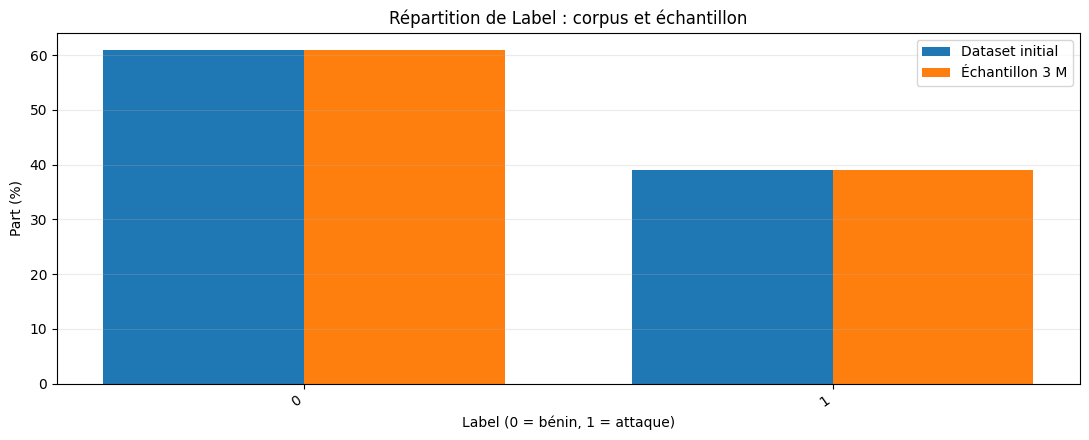

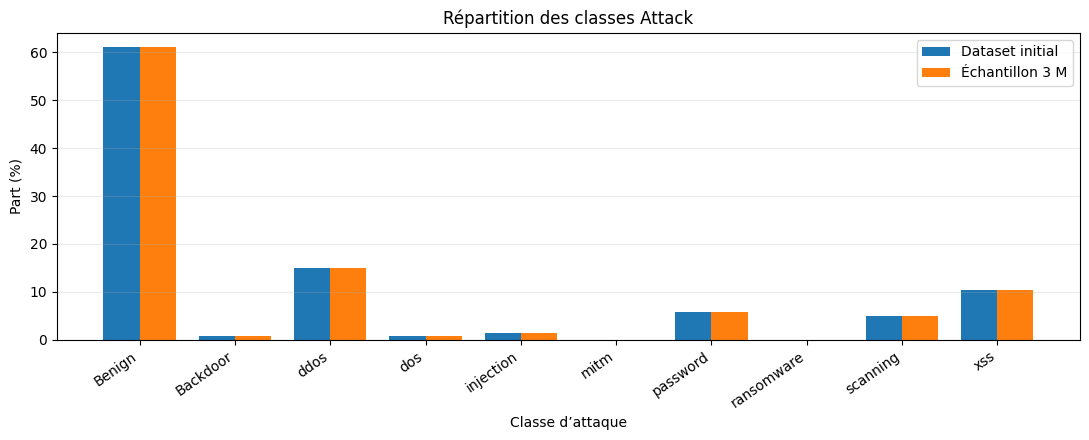

,Dataset initial (%),Échantillon (%)
Benign,61.0176,61.0176
ddos,15.0480,15.0480
xss,10.2994,10.2994
password,5.7949,5.7949
scanning,4.9381,4.9381
injection,1.3873,1.3873
dos,0.7393,0.7393
Backdoor,0.7390,0.7390
mitm,0.0218,0.0218
ransomware,0.0144,0.0144


In [10]:
population_by_attack = {}
for key, count in manifest["stratum_population_counts"].items():
    _, attack = key.split("|", 1)
    population_by_attack[attack] = population_by_attack.get(attack, 0) + int(count)

sample_label_pct = 100 * df_sample["Label"].value_counts(normalize=True).sort_index()
pop_label_pct = pd.Series({
    0: 100 * sum(v for k, v in manifest["stratum_population_counts"].items() if k.startswith("0|")) / manifest["population_rows"],
    1: 100 * sum(v for k, v in manifest["stratum_population_counts"].items() if k.startswith("1|")) / manifest["population_rows"],
})

attack_sample_pct = 100 * df_sample["Attack"].astype(str).value_counts(normalize=True)
attack_population_pct = 100 * pd.Series(population_by_attack) / manifest["population_rows"]
attack_compare = pd.concat([
    attack_population_pct.rename("Dataset initial (%)"),
    attack_sample_pct.rename("Échantillon (%)")
], axis=1).fillna(0).sort_values("Dataset initial (%)", ascending=False)

def compare_bars(population_pct, sample_pct, title, xlabel):
    labels = list(population_pct.index)
    x = np.arange(len(labels))
    width = 0.38
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.bar(x - width / 2, [population_pct.get(k, 0) for k in labels], width, label="Dataset initial")
    ax.bar(x + width / 2, [sample_pct.get(k, 0) for k in labels], width, label="Échantillon 3 M")
    ax.set_xticks(x, labels, rotation=35, ha="right")
    ax.set_ylabel("Part (%)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

compare_bars(pop_label_pct, sample_label_pct, "Répartition de Label : corpus et échantillon", "Label (0 = bénin, 1 = attaque)")
compare_bars(attack_population_pct, attack_sample_pct, "Répartition des classes Attack", "Classe d’attaque")
display(attack_compare.round(4))

### 3.4 Exploration visuelle — manquants, distributions et relations

Aucune valeur manquante dans l’échantillon.


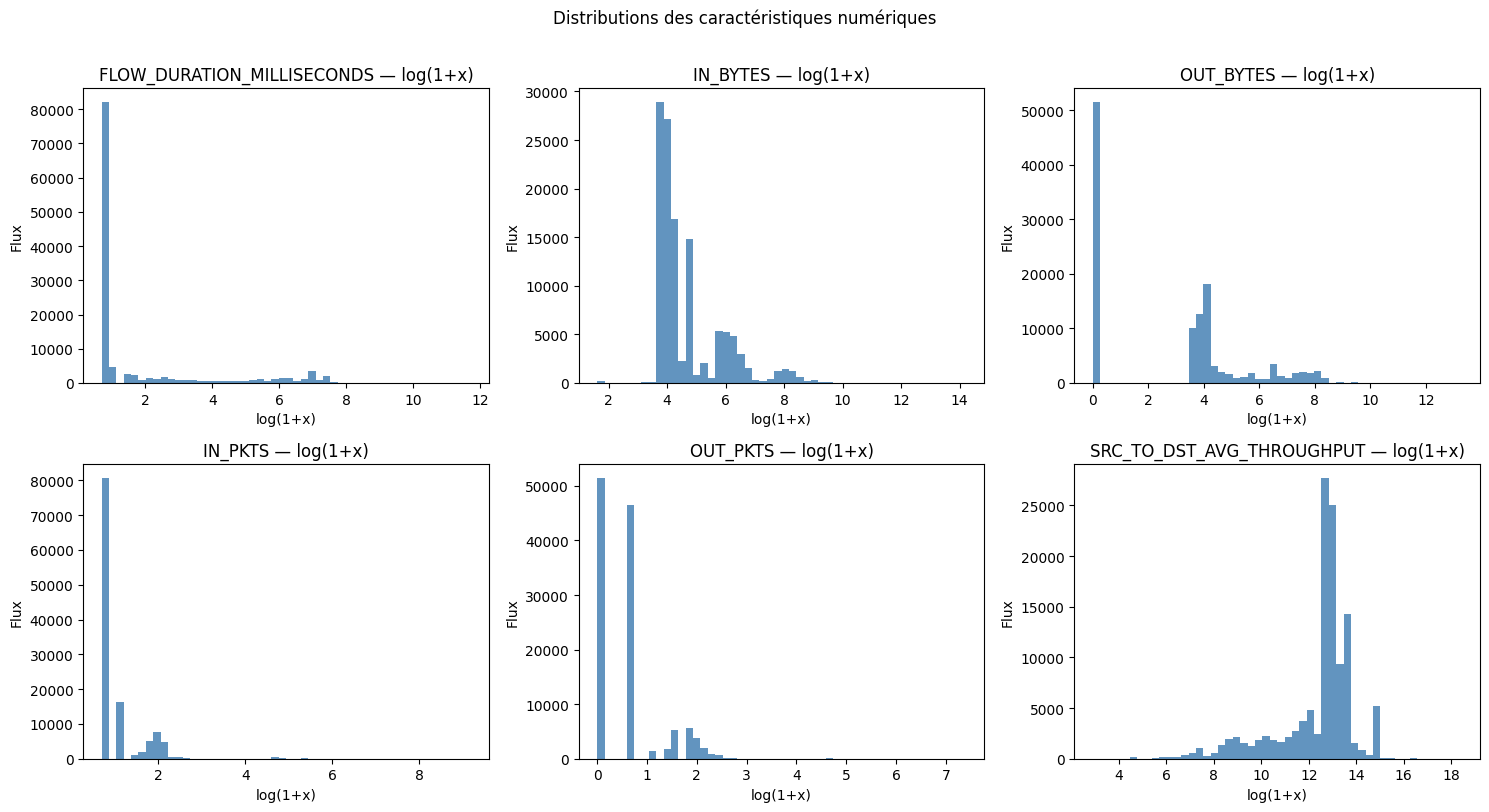

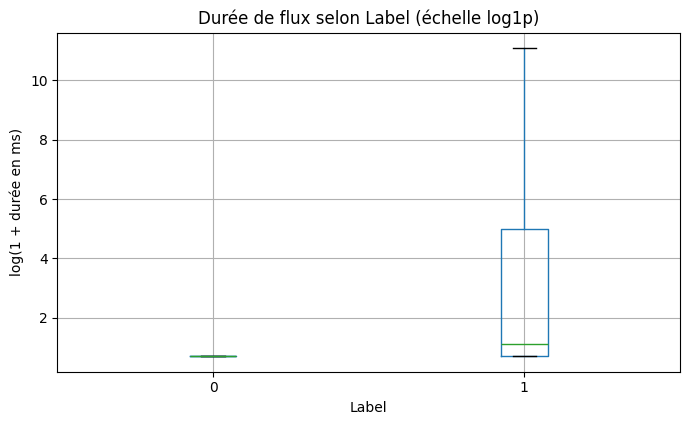

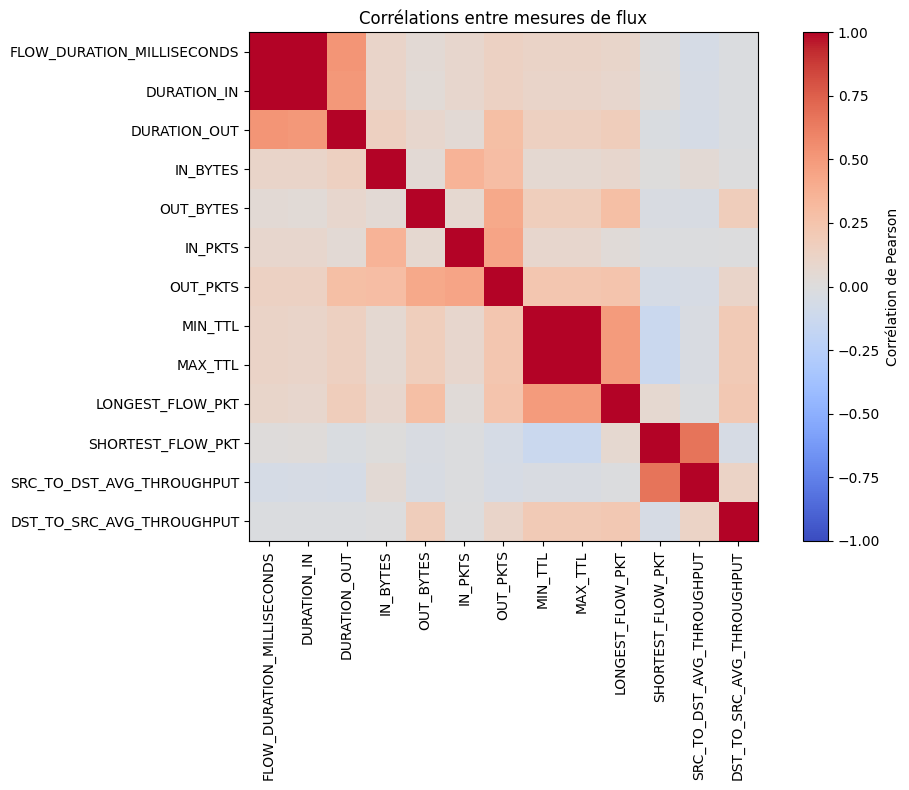

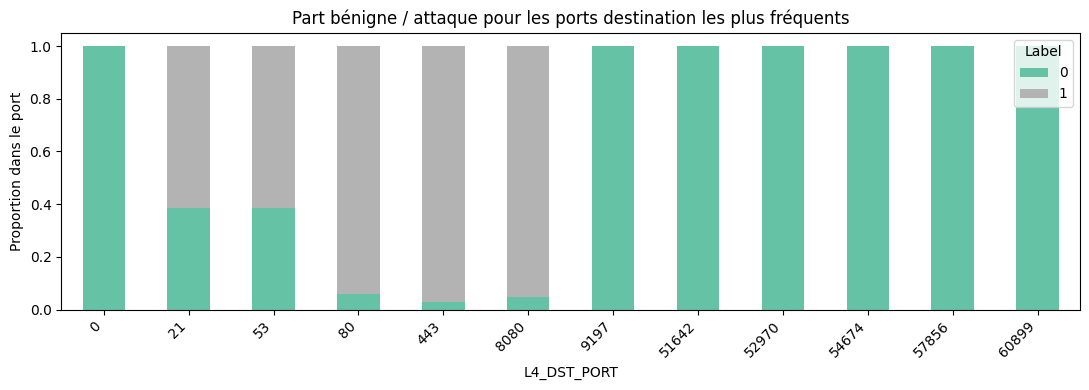

In [11]:
missing_pct = 100 * df_sample.isna().mean()
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
if len(missing_pct):
    fig, ax = plt.subplots(figsize=(11, max(3, 0.28 * len(missing_pct))))
    missing_pct.sort_values().plot.barh(ax=ax, color="darkorange")
    ax.set_xlabel("Valeurs manquantes (%)")
    ax.set_title("Valeurs manquantes par variable")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune valeur manquante dans l’échantillon.")

plot_n = min(120_000, len(df_sample))
plot_df = df_sample.sample(plot_n, random_state=RANDOM_STATE)
plot_features = [c for c in [
    "FLOW_DURATION_MILLISECONDS", "IN_BYTES", "OUT_BYTES",
    "IN_PKTS", "OUT_PKTS", "SRC_TO_DST_AVG_THROUGHPUT"
] if c in plot_df.columns]
if plot_features:
    ncols = 3
    nrows = int(np.ceil(len(plot_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.asarray(axes).reshape(-1)
    for ax, col in zip(axes, plot_features):
        values = pd.to_numeric(plot_df[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        values = values[values >= 0]
        ax.hist(np.log1p(values), bins=50, color="steelblue", alpha=0.85)
        ax.set_title(f"{col} — log(1+x)")
        ax.set_xlabel("log(1+x)")
        ax.set_ylabel("Flux")
    for ax in axes[len(plot_features):]:
        ax.remove()
    plt.suptitle("Distributions des caractéristiques numériques", y=1.01)
    plt.tight_layout()
    plt.show()

if "FLOW_DURATION_MILLISECONDS" in plot_df:
    valid_duration = plot_df[["Label", "FLOW_DURATION_MILLISECONDS"]].copy()
    valid_duration["log_duree"] = np.log1p(pd.to_numeric(valid_duration["FLOW_DURATION_MILLISECONDS"], errors="coerce").clip(lower=0))
    fig, ax = plt.subplots(figsize=(7, 4.5))
    valid_duration.boxplot(column="log_duree", by="Label", ax=ax, showfliers=False)
    ax.set_title("Durée de flux selon Label (échelle log1p)")
    ax.set_xlabel("Label")
    ax.set_ylabel("log(1 + durée en ms)")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

corr_review = [c for c in [
    "FLOW_DURATION_MILLISECONDS", "DURATION_IN", "DURATION_OUT",
    "IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS", "MIN_TTL",
    "MAX_TTL", "LONGEST_FLOW_PKT", "SHORTEST_FLOW_PKT",
    "SRC_TO_DST_AVG_THROUGHPUT", "DST_TO_SRC_AVG_THROUGHPUT"
] if c in plot_df.columns]
if len(corr_review) >= 2:
    corr = plot_df[corr_review].replace([np.inf, -np.inf], np.nan).corr()
    fig, ax = plt.subplots(figsize=(11, 8))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    fig.colorbar(im, ax=ax, label="Corrélation de Pearson")
    ax.set_xticks(range(len(corr_review)), corr_review, rotation=90)
    ax.set_yticks(range(len(corr_review)), corr_review)
    ax.set_title("Corrélations entre mesures de flux")
    plt.tight_layout()
    plt.show()

if "L4_DST_PORT" in plot_df:
    top_ports = plot_df["L4_DST_PORT"].value_counts().head(12).index
    port_frame = plot_df.loc[plot_df["L4_DST_PORT"].isin(top_ports), ["L4_DST_PORT", "Label"]]
    port_table = pd.crosstab(port_frame["L4_DST_PORT"], port_frame["Label"], normalize="index")
    port_table.plot(kind="bar", stacked=True, figsize=(11, 4), colormap="Set2")
    plt.title("Part bénigne / attaque pour les ports destination les plus fréquents")
    plt.xlabel("L4_DST_PORT")
    plt.ylabel("Proportion dans le port")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

del plot_df

**Lecture de l’exploration.** Les proportions sont comparées au corpus initial ; les histogrammes de volumes utilisent `log(1+x)` afin de rendre visibles les flux courts et les queues lourdes. Les graphiques de corrélation et de ports servent à formuler des hypothèses, pas à établir une causalité.

## 4. CRISP-DM — Data Preparation : nettoyage

Règles appliquées : retirer uniquement les lignes dont `Label` n’est pas 0/1 ou dont `Label` contredit `Attack`; convertir `+inf` et `-inf` en valeurs manquantes ; garder les flux dupliqués car ils peuvent être des événements répétés. Les imputeurs seront ajustés sur le train de chaque pli. `Attack`, les timestamps, les IP, l’identifiant DNS et le port source sont exclus des prédicteurs pour limiter la fuite de cible et les raccourcis propres à la capture.

Échantillon initial : 3,000,000
Cibles invalides supprimées : 0
Incohérences Label / Attack supprimées : 0
Lignes de modélisation : 3,000,000
Doublons conservés : 93,790
Mémoire de modélisation : 1.03 Go


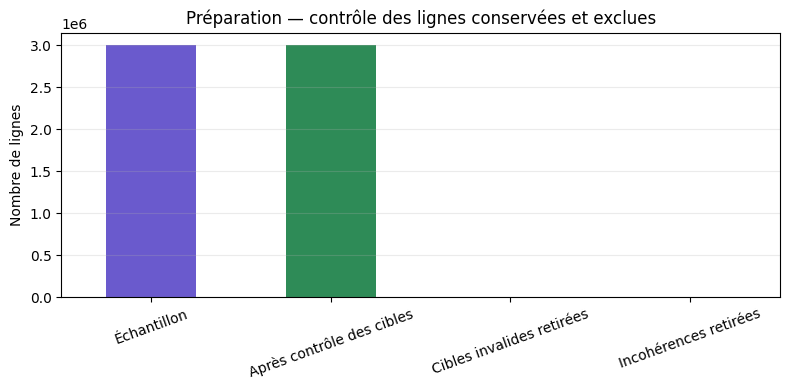

In [12]:
del df_sample
gc.collect()

all_columns = pd.read_csv(SAMPLE_PATH, compression="gzip", nrows=0).columns.tolist()
TARGET = "Label"
ATTACK = "Attack"
ROW_ID = "__source_row__"
MANUAL_EXCLUSIONS = {
    ROW_ID, ATTACK, "FLOW_START_MILLISECONDS", "FLOW_END_MILLISECONDS",
    "IPV4_SRC_ADDR", "IPV4_DST_ADDR", "DNS_QUERY_ID", "L4_SRC_PORT"
}
model_columns = [c for c in all_columns if c != ROW_ID]
df_model = pd.read_csv(
    SAMPLE_PATH, compression="gzip", usecols=model_columns,
    low_memory=False, dtype={"Attack": "category"}
)

label_numeric = pd.to_numeric(df_model[TARGET], errors="coerce")
attack_text = df_model[ATTACK].astype("string").fillna("Unknown")
valid_label = label_numeric.isin([0, 1])
consistent = ~((label_numeric.eq(0) & attack_text.ne("Benign")) |
               (label_numeric.eq(1) & attack_text.eq("Benign")))
keep_rows = valid_label & consistent
removed_invalid = int((~valid_label).sum())
removed_inconsistent = int((valid_label & ~consistent).sum())
if not keep_rows.all():
    df_model = df_model.loc[keep_rows].copy().reset_index(drop=True)
    label_numeric = label_numeric.loc[keep_rows].reset_index(drop=True)
    attack_text = attack_text.loc[keep_rows].reset_index(drop=True)
df_model[TARGET] = label_numeric.astype("int8")
df_model[ATTACK] = attack_text.astype("category")

numeric_cols = [c for c in df_model.select_dtypes(include=np.number).columns
                if c not in {TARGET}]
for col in numeric_cols:
    df_model[col] = pd.to_numeric(df_model[col], errors="coerce").astype("float32")
for col in numeric_cols:
    values = df_model[col].to_numpy(copy=False)
    inf_mask = np.isinf(values)
    if inf_mask.any():
        values[inf_mask] = np.nan

print("Échantillon initial :", f"{SAMPLE_SIZE:,}")
print("Cibles invalides supprimées :", removed_invalid)
print("Incohérences Label / Attack supprimées :", removed_inconsistent)
print("Lignes de modélisation :", f"{len(df_model):,}")
print("Doublons conservés :", f"{duplicate_count:,}")
print("Mémoire de modélisation :", round(df_model.memory_usage(deep=True).sum() / 1e9, 2), "Go")

# Visualiser le volume conservé et les lignes retirées pendant le nettoyage.
cleaning_counts = pd.Series({
    "Échantillon": SAMPLE_SIZE,
    "Après contrôle des cibles": len(df_model),
    "Cibles invalides retirées": removed_invalid,
    "Incohérences retirées": removed_inconsistent,
})
fig, ax = plt.subplots(figsize=(8, 4))
cleaning_counts.plot.bar(ax=ax, color=["slateblue", "seagreen", "darkorange", "indianred"])
ax.set_ylabel("Nombre de lignes")
ax.set_title("Préparation — contrôle des lignes conservées et exclues")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 4.1 Définir les partitions avant la sélection et le prétraitement

Le test représente 20 % de l’échantillon. La stratification utilise les combinaisons `Label`/`Attack`, afin que les classes rares restent présentes dans les partitions. Les poids de sondage, dérivés des effectifs initiaux et des quotas, corrigent les très faibles écarts d’arrondi lors des métriques et de l’apprentissage.

In [13]:
from sklearn.model_selection import train_test_split

labels = df_model[TARGET].to_numpy(dtype=np.int8)
attack_levels = [str(value) for value in df_model[ATTACK].cat.categories]
attack_codes = df_model[ATTACK].cat.codes.to_numpy(dtype=np.int16)
# Un code entier représente chaque combinaison Label / Attack, sans construire 3 M de chaînes.
strata = labels.astype(np.int16) * len(attack_levels) + attack_codes
row_indices = np.arange(len(df_model), dtype=np.int64)
train_idx, test_idx = train_test_split(
    row_indices, test_size=0.20, random_state=RANDOM_STATE,
    stratify=strata
)

population_counts = manifest["stratum_population_counts"]
sample_counts = manifest["stratum_sample_counts"]
attack_code_by_name = {name: code for code, name in enumerate(attack_levels)}
weight_lookup = np.ones((2, len(attack_levels)), dtype=np.float32)
for key, sample_count in sample_counts.items():
    label_text, attack_name = key.split("|", 1)
    weight_lookup[int(label_text), attack_code_by_name[attack_name]] = (
        population_counts[key] / sample_count
    )
sampling_weight = weight_lookup[labels, attack_codes]
sampling_weight /= sampling_weight.mean()

split_rows = []
for name, idx in [("train", train_idx), ("test", test_idx)]:
    part = pd.DataFrame({"Label": labels[idx], "Attack": attack_codes[idx]})
    split_rows.append({
        "partition": name, "lignes": len(idx),
        "% Label 1": 100 * np.average(labels[idx], weights=sampling_weight[idx]),
        "classes Attack présentes": part["Attack"].nunique(),
    })
display(pd.DataFrame(split_rows).round(3))
print("Poids de sondage normalisés — min / max :",
      float(sampling_weight.min()), float(sampling_weight.max()))
print("Parts de lignes communes aux partitions :", len(np.intersect1d(train_idx, test_idx)))

,partition,lignes,% Label 1,classes Attack présentes
0,train,2400000,38.982,10
1,test,600000,38.982,10


Poids de sondage normalisés — min / max : 0.9997278451919556 1.0007364749908447
Parts de lignes communes aux partitions : 0


### 4.2 Sélection des variables, ajustée sur le train


La sélection combine des règles de rôle et des contrôles calculés uniquement sur le train : colonnes entièrement manquantes ou constantes, variables dont plus de la moitié des valeurs sont manquantes, puis une variable retirée dans chaque paire de mesures numériques corrélées au-delà de 0,98. Les codes catégoriels (ports, protocoles, flags) ne sont pas évalués par corrélation de Pearson.

,étape,nombre,retirées
0,Variables candidates après règles métier,47,
1,Plus de 50 % manquant,0,
2,Constantes / entièrement manquantes,0,
3,"Redondance numérique (|r| > 0,98)",4,"DST_TO_SRC_IAT_STDDEV, DURATION_IN, MAX_IP_PKT..."
4,Variables retenues,43,


,variable 1,variable 2,|corrélation| moyenne
2,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,1.000000
1,MIN_TTL,MAX_TTL,0.999714
0,FLOW_DURATION_MILLISECONDS,DURATION_IN,0.994600
3,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_STDDEV,0.986706


,colonne / groupe,décision
0,Label,cible à prédire
1,Attack,représentation détaillée de la cible — fuite d...
2,FLOW_START_MILLISECONDS / FLOW_END_MILLISECONDS,horodatages bruts — risque d’apprendre la capture
3,IPV4_SRC_ADDR / IPV4_DST_ADDR,identifiants d’hôtes — risque de raccourci pro...
4,DNS_QUERY_ID,identifiant de transaction à forte cardinalité
5,L4_SRC_PORT,exclu du modèle principal pour limiter les rac...
6,__source_row__,"index de provenance, jamais une caractéristique"


Variables retenues : ['L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_OUT', 'MIN_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX', 'DST_TO_SRC_IAT_AVG']
Variables catégorielles traitées comme catégories : ['L4_DST_PORT', 'PROTO

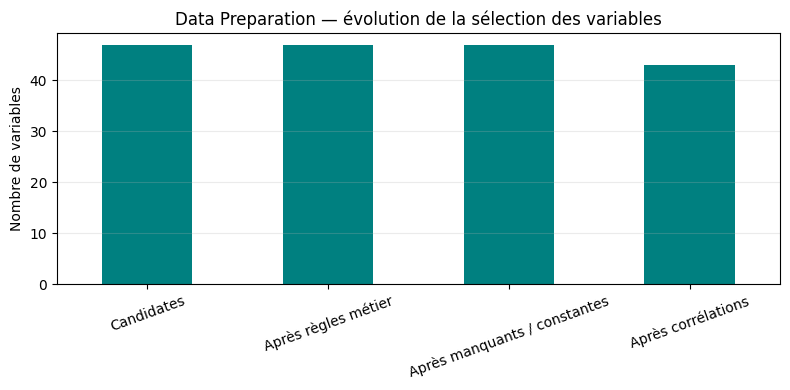

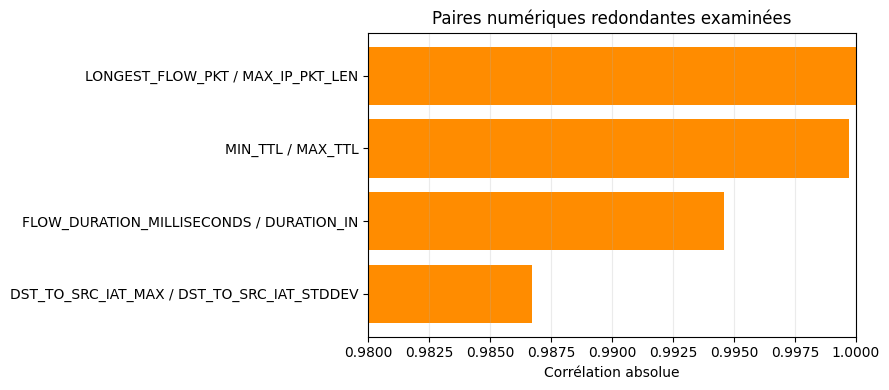

In [14]:
CATEGORICAL_CANDIDATES = {
    "L4_DST_PORT", "PROTOCOL", "L7_PROTO", "TCP_FLAGS",
    "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "ICMP_TYPE",
    "ICMP_IPV4_TYPE", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE"
}
feature_candidates = [
    c for c in df_model.columns
    if c not in MANUAL_EXCLUSIONS and c != TARGET
]
missing_rate = {}
unique_count = {}
for col in feature_candidates:
    train_col = df_model[col].iloc[train_idx]
    missing_rate[col] = float(train_col.isna().mean())
    unique_count[col] = int(train_col.nunique(dropna=False))

removed_missing = {c for c in feature_candidates if missing_rate[c] > 0.50}
removed_constant = {c for c in feature_candidates if unique_count[c] <= 1}
selected = [c for c in feature_candidates if c not in removed_missing | removed_constant]

continuous_for_corr = [c for c in selected if c not in CATEGORICAL_CANDIDATES]
rng_selection = np.random.default_rng(RANDOM_STATE)
corr_rows = rng_selection.choice(
    train_idx, size=min(100_000, len(train_idx)), replace=False
)
correlated_pairs = []
removed_correlated = set()
if len(continuous_for_corr) > 1:
    corr_frame = df_model.iloc[corr_rows][continuous_for_corr]
    corr_matrix = corr_frame.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
    for j, col in enumerate(upper.columns):
        above = upper.iloc[:j, j]
        matches = above[above > 0.98]
        if len(matches):
            for prior_col, value in matches.items():
                correlated_pairs.append((prior_col, col, float(value)))
            removed_correlated.add(col)
selected_features = [c for c in selected if c not in removed_correlated]
if not selected_features:
    raise ValueError("La sélection a supprimé toutes les variables explicatives.")

selection_report = pd.DataFrame([
    {"étape": "Variables candidates après règles métier", "nombre": len(feature_candidates), "retirées": ""},
    {"étape": "Plus de 50 % manquant", "nombre": len(removed_missing), "retirées": ", ".join(sorted(removed_missing))},
    {"étape": "Constantes / entièrement manquantes", "nombre": len(removed_constant), "retirées": ", ".join(sorted(removed_constant))},
    {"étape": "Redondance numérique (|r| > 0,98)", "nombre": len(removed_correlated), "retirées": ", ".join(sorted(removed_correlated))},
    {"étape": "Variables retenues", "nombre": len(selected_features), "retirées": ""},
])
display(selection_report)
display(pd.DataFrame(correlated_pairs, columns=["variable 1", "variable 2", "|corrélation| moyenne"])
        .sort_values("|corrélation| moyenne", ascending=False))
manual_exclusion_reasons = {
    "Label": "cible à prédire",
    "Attack": "représentation détaillée de la cible — fuite de cible",
    "FLOW_START_MILLISECONDS / FLOW_END_MILLISECONDS": "horodatages bruts — risque d’apprendre la capture",
    "IPV4_SRC_ADDR / IPV4_DST_ADDR": "identifiants d’hôtes — risque de raccourci propre au réseau",
    "DNS_QUERY_ID": "identifiant de transaction à forte cardinalité",
    "L4_SRC_PORT": "exclu du modèle principal pour limiter les raccourcis de capture",
    "__source_row__": "index de provenance, jamais une caractéristique"
}
display(pd.DataFrame([
    {"colonne / groupe": col, "décision": reason}
    for col, reason in manual_exclusion_reasons.items()
]))
print("Variables retenues :", selected_features)
print("Variables catégorielles traitées comme catégories :",
      [c for c in selected_features if c in CATEGORICAL_CANDIDATES])

# Résumer visuellement le nombre de variables à chaque étape de la sélection.
selection_counts = pd.Series({
    "Candidates": len(feature_candidates),
    "Après règles métier": len(feature_candidates),
    "Après manquants / constantes": len(selected),
    "Après corrélations": len(selected_features),
})
fig, ax = plt.subplots(figsize=(8, 4))
selection_counts.plot.bar(ax=ax, color="teal")
ax.set_ylabel("Nombre de variables")
ax.set_title("Data Preparation — évolution de la sélection des variables")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
if correlated_pairs:
    pair_plot = pd.DataFrame(correlated_pairs, columns=["variable 1", "variable 2", "corrélation"])
    pair_plot = pair_plot.nlargest(15, "corrélation").sort_values("corrélation")
    fig, ax = plt.subplots(figsize=(9, max(4, 0.28 * len(pair_plot))))
    ax.barh(pair_plot["variable 1"] + " / " + pair_plot["variable 2"],
            pair_plot["corrélation"], color="darkorange")
    ax.set(xlim=(0.98, 1.0), xlabel="Corrélation absolue", title="Paires numériques redondantes examinées")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


## 5. CRISP-DM — Modeling : réglage et validation croisée

Les modèles binaires apprennent exclusivement `Label` (0 = bénin, 1 = attaque). Une GridSearchCV règle leurs hyperparamètres sur un sous-échantillon stratifié du train ; les prétraitements restent dans chaque pipeline de recherche. Les meilleurs paramètres sont ensuite utilisés dans les mêmes cinq plis StratifiedKFold pour produire des prédictions hors pli. Pour XGBoost, la recherche est limitée à 50 ou 100 arbres et une profondeur de 3 ou 4 ; la validation utilise un arrêt anticipé après 15 itérations sans amélioration. Le test reste tenu à l’écart jusqu’à l’évaluation finale.


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss, hinge_loss
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from time import perf_counter

N_SPLITS = 5
N_ESTIMATORS = 100
MAX_DEPTH = 4
N_JOBS = -1
categorical_features = [c for c in selected_features if c in CATEGORICAL_CANDIDATES]
numeric_features = [c for c in selected_features if c not in categorical_features]

def make_preprocessor(features=None):
    features = selected_features if features is None else features
    categorical = [c for c in features if c in CATEGORICAL_CANDIDATES]
    numeric = [c for c in features if c not in categorical]
    transformers = []
    if numeric:
        numeric_pipe = Pipeline([
            ("imputation", SimpleImputer(strategy="median", keep_empty_features=True))
        ])
        transformers.append(("mesures", numeric_pipe, numeric))
    if categorical:
        categorical_pipe = Pipeline([
            ("imputation", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("encodage", OneHotEncoder(
                handle_unknown="infrequent_if_exist", min_frequency=100,
                max_categories=64, sparse_output=True, dtype=np.float32
            ))
        ])
        transformers.append(("codes", categorical_pipe, categorical))
    return ColumnTransformer(
        transformers, remainder="drop", sparse_threshold=1.0,
        verbose_feature_names_out=True
    )

def signed_log1p(values):
    values = np.asarray(values, dtype=np.float32)
    return np.sign(values) * np.log1p(np.abs(values))

def make_scaled_preprocessor():
    numeric_pipe = Pipeline([
        ("imputation", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("log_signe", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
        ("standardisation", StandardScaler(with_mean=False)),
    ])
    categorical_pipe = Pipeline([
        ("imputation", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("encodage", OneHotEncoder(
            handle_unknown="infrequent_if_exist", min_frequency=100,
            max_categories=64, sparse_output=True, dtype=np.float32,
        )),
    ])
    transformers = []
    if numeric_features:
        transformers.append(("mesures", numeric_pipe, numeric_features))
    if categorical_features:
        transformers.append(("codes", categorical_pipe, categorical_features))
    return ColumnTransformer(transformers, sparse_threshold=1.0)

def balanced_training_weights(indices):
    base_weights = sampling_weight[indices]
    counts = np.bincount(labels[indices], weights=base_weights, minlength=2)
    positive_factor = counts[0] / max(counts[1], 1e-12)
    return base_weights * np.where(labels[indices] == 1, positive_factor, 1.0)

def make_model(y_fit, weights_fit, seed=RANDOM_STATE,
               model_params=None, n_estimators=N_ESTIMATORS,
               early_stopping_rounds=None):
    class_counts = np.bincount(y_fit, weights=weights_fit, minlength=2)
    scale_pos_weight = class_counts[0] / max(class_counts[1], 1e-12)
    params = {
        "n_estimators": n_estimators, "max_depth": MAX_DEPTH,
        "learning_rate": 0.06, "subsample": 0.7, "colsample_bytree": 0.7,
        "min_child_weight": 5, "reg_lambda": 5.0, "max_bin": 128,
        "objective": "binary:logistic", "eval_metric": "logloss",
        "tree_method": "hist", "scale_pos_weight": scale_pos_weight,
        "n_jobs": N_JOBS, "random_state": seed,
    }
    params.update(model_params or {})
    params["scale_pos_weight"] = scale_pos_weight
    if early_stopping_rounds is not None:
        params["early_stopping_rounds"] = early_stopping_rounds
    return XGBClassifier(**params)

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
y_train = labels[train_idx]
strata_train = strata[train_idx]

TUNING_SAMPLE_SIZE = min(60_000, len(train_idx))
tuning_idx, _ = train_test_split(
    train_idx, train_size=TUNING_SAMPLE_SIZE, random_state=RANDOM_STATE,
    stratify=labels[train_idx]
)
tuning_weights = balanced_training_weights(tuning_idx)
tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search_specs = {
    "XGBoost": (
        make_preprocessor(),
        make_model(labels[tuning_idx], sampling_weight[tuning_idx]),
        {"classifier__max_depth": [3, 4], "classifier__n_estimators": [50, 100]},
    ),
    "Régression logistique": (
        make_scaled_preprocessor(),
        SGDClassifier(loss="log_loss", penalty="l2", max_iter=10, tol=None,
                      average=True, random_state=RANDOM_STATE, n_jobs=N_JOBS),
        {"classifier__alpha": [1e-4, 1e-5]},
    ),
    "Arbre de décision": (
        make_preprocessor(),
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"classifier__max_depth": [4, 6], "classifier__min_samples_leaf": [250, 500]},
    ),
    "SVM linéaire (SGD)": (
        make_scaled_preprocessor(),
        SGDClassifier(loss="hinge", penalty="l2", max_iter=5, tol=None,
                      average=True, random_state=RANDOM_STATE, n_jobs=N_JOBS),
        {"classifier__alpha": [1e-3, 1e-4]},
    ),
}


### Exécution du GridSearchCV + résultats

GridSearchCV terminé — XGBoost: {'max_depth': 4, 'n_estimators': 100}
GridSearchCV terminé — Régression logistique: {'alpha': 1e-05}
GridSearchCV terminé — Arbre de décision: {'max_depth': 6, 'min_samples_leaf': 500}
GridSearchCV terminé — SVM linéaire (SGD): {'alpha': 0.0001}


,modèle,paramètres,PR-AUC CV moyenne,écart-type,PR-AUC train moyenne
9,Arbre de décision,"{'max_depth': 6, 'min_samples_leaf': 500}",0.9545,0.0004,0.9553
8,Arbre de décision,"{'max_depth': 6, 'min_samples_leaf': 250}",0.9530,0.0017,0.9545
6,Arbre de décision,"{'max_depth': 4, 'min_samples_leaf': 250}",0.9260,0.0013,0.9263
7,Arbre de décision,"{'max_depth': 4, 'min_samples_leaf': 500}",0.9246,0.0014,0.9247
5,Régression logistique,{'alpha': 1e-05},0.9516,0.0021,0.9523
4,Régression logistique,{'alpha': 0.0001},0.9508,0.0020,0.9510
11,SVM linéaire (SGD),{'alpha': 0.0001},0.9489,0.0018,0.9490
10,SVM linéaire (SGD),{'alpha': 0.001},0.9462,0.0016,0.9464
3,XGBoost,"{'max_depth': 4, 'n_estimators': 100}",0.9711,0.0006,0.9719
1,XGBoost,"{'max_depth': 3, 'n_estimators': 100}",0.9685,0.0008,0.9690


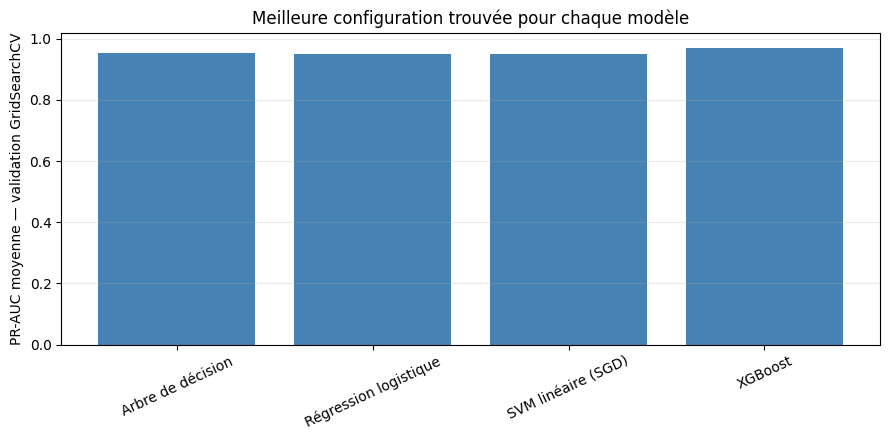

In [16]:
best_params_by_model = {}
grid_search_rows = []
for model_name, (preprocessor, estimator, param_grid) in search_specs.items():
    search_pipeline = Pipeline([
        ("preparation", preprocessor),
        ("classifier", estimator),
    ])
    search = GridSearchCV(
        search_pipeline, param_grid=param_grid, scoring="average_precision",
        cv=tuning_cv, n_jobs=1, refit=False, return_train_score=True,
        error_score="raise",
    )
    search.fit(
        df_model.iloc[tuning_idx][selected_features], labels[tuning_idx],
        classifier__sample_weight=tuning_weights,
    )
    best_params_by_model[model_name] = {
        key.replace("classifier__", ""): value
        for key, value in search.best_params_.items()
    }
    for row_i, params in enumerate(search.cv_results_["params"]):
        grid_search_rows.append({
            "modèle": model_name,
            "paramètres": str({k.replace("classifier__", ""): v for k, v in params.items()}),
            "PR-AUC CV moyenne": search.cv_results_["mean_test_score"][row_i],
            "écart-type": search.cv_results_["std_test_score"][row_i],
            "PR-AUC train moyenne": search.cv_results_["mean_train_score"][row_i],
        })
    print(f"GridSearchCV terminé — {model_name}: {best_params_by_model[model_name]}")

grid_search_results = pd.DataFrame(grid_search_rows).sort_values(
    ["modèle", "PR-AUC CV moyenne"], ascending=[True, False]
)
display(grid_search_results.round(4))

best_grid_scores = grid_search_results.groupby("modèle", sort=False).first().reset_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(best_grid_scores["modèle"], best_grid_scores["PR-AUC CV moyenne"], color="steelblue")
ax.set_ylabel("PR-AUC moyenne — validation GridSearchCV")
ax.set_title("Meilleure configuration trouvée pour chaque modèle")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Évaluation croisée XGBoost (OOF) + courbes de perte

XGBoost — pli 1/5 terminé — PR-AUC 0.9723
XGBoost — pli 2/5 terminé — PR-AUC 0.9720
XGBoost — pli 3/5 terminé — PR-AUC 0.9724
XGBoost — pli 4/5 terminé — PR-AUC 0.9724
XGBoost — pli 5/5 terminé — PR-AUC 0.9723


,pli,lignes validation,fit modèle (s),PR-AUC apprentissage,PR-AUC,ROC-AUC,perte apprentissage,perte validation,arbres utilisés
0,1,480000,73.2535,0.9724,0.9723,0.9821,0.1635,0.1639,100
1,2,480000,79.7498,0.9721,0.9720,0.9818,0.1640,0.1646,100
2,3,480000,65.3035,0.9724,0.9724,0.9821,0.1628,0.1630,100
3,4,480000,65.0604,0.9724,0.9724,0.9823,0.1634,0.1633,100
4,5,480000,65.4804,0.9721,0.9723,0.9821,0.1639,0.1629,100


,moyenne CV,écart-type CV
PR-AUC,0.972284,0.000185
ROC-AUC,0.982066,0.000184


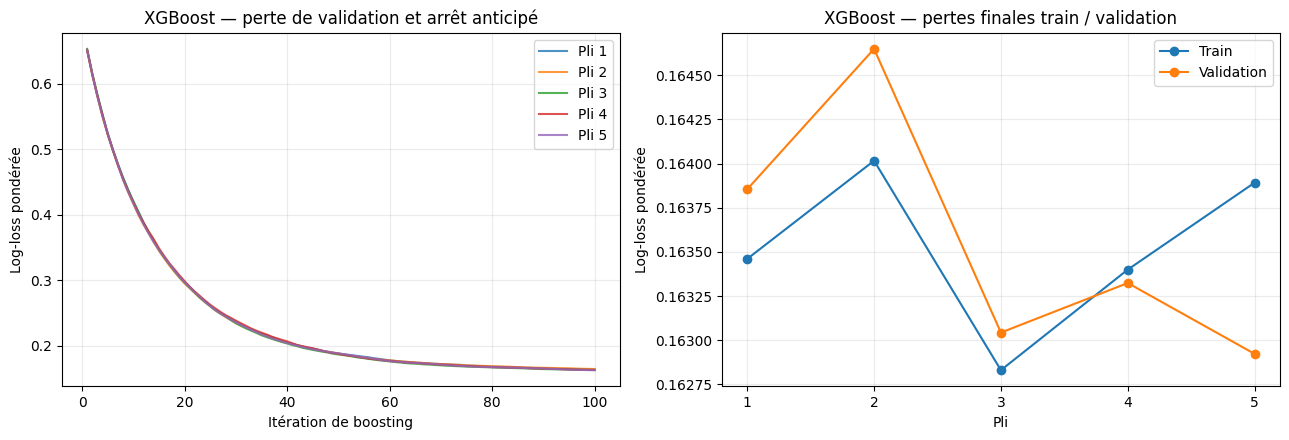

In [17]:
oof_probability = np.full(len(train_idx), np.nan, dtype=np.float32)
xgb_fold_train_probability = np.full(len(train_idx), np.nan, dtype=np.float32)
fold_results = []
xgb_loss_histories = []

for fold, (fit_pos, valid_pos) in enumerate(
    cv.split(np.zeros(len(train_idx)), strata_train), start=1
):
    fit_idx = train_idx[fit_pos]
    valid_idx = train_idx[valid_pos]
    x_fit_raw = df_model.iloc[fit_idx][selected_features]
    x_valid_raw = df_model.iloc[valid_idx][selected_features]
    fold_preprocessor = make_preprocessor()
    x_fit = fold_preprocessor.fit_transform(x_fit_raw)
    x_valid = fold_preprocessor.transform(x_valid_raw)
    fold_model = make_model(
        labels[fit_idx], sampling_weight[fit_idx], seed=RANDOM_STATE + fold,
        model_params=best_params_by_model["XGBoost"],
        early_stopping_rounds=15,
    )
    model_fit_started = perf_counter()
    fold_model.fit(
        x_fit, labels[fit_idx], sample_weight=sampling_weight[fit_idx],
        eval_set=[(x_valid, labels[valid_idx])],
        sample_weight_eval_set=[sampling_weight[valid_idx]],
        verbose=False,
    )
    fold_fit_seconds = perf_counter() - model_fit_started
    eval_history = fold_model.evals_result()
    valid_loss_curve = eval_history["validation_0"]["logloss"]
    xgb_loss_histories.append(valid_loss_curve)
    train_probability = fold_model.predict_proba(x_fit)[:, 1]
    probability = fold_model.predict_proba(x_valid)[:, 1]
    xgb_fold_train_probability[fit_pos] = train_probability.astype(np.float32)
    oof_probability[valid_pos] = probability.astype(np.float32)
    fold_results.append({
        "pli": fold,
        "lignes validation": len(valid_idx),
        "fit modèle (s)": fold_fit_seconds,
        "PR-AUC apprentissage": average_precision_score(
            labels[fit_idx], train_probability, sample_weight=sampling_weight[fit_idx]
        ),
        "PR-AUC": average_precision_score(
            labels[valid_idx], probability, sample_weight=sampling_weight[valid_idx]
        ),
        "ROC-AUC": roc_auc_score(
            labels[valid_idx], probability, sample_weight=sampling_weight[valid_idx]
        ),
        "perte apprentissage": log_loss(
            labels[fit_idx], train_probability, labels=[0, 1],
            sample_weight=sampling_weight[fit_idx]
        ),
        "perte validation": log_loss(
            labels[valid_idx], probability, labels=[0, 1],
            sample_weight=sampling_weight[valid_idx]
        ),
        "arbres utilisés": int(getattr(fold_model, "best_iteration", len(valid_loss_curve) - 1)) + 1,
    })
    print(f"XGBoost — pli {fold}/{N_SPLITS} terminé — PR-AUC {fold_results[-1]['PR-AUC']:.4f}")
    del x_fit_raw, x_valid_raw, x_fit, x_valid, train_probability, probability
    del fold_preprocessor, fold_model
    gc.collect()

fold_results = pd.DataFrame(fold_results)
display(fold_results.round(4))
display(fold_results[["PR-AUC", "ROC-AUC"]].agg(["mean", "std"]).T.rename(
    columns={"mean": "moyenne CV", "std": "écart-type CV"}
))
if not np.isfinite(oof_probability).all():
    raise RuntimeError("Certaines lignes du train n’ont pas reçu de prédiction hors pli.")
if not np.isfinite(xgb_fold_train_probability).all():
    raise RuntimeError("Certaines lignes du train n’ont pas reçu de prédiction d’apprentissage de pli.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for fold, valid_curve in enumerate(xgb_loss_histories, start=1):
    axes[0].plot(np.arange(1, len(valid_curve) + 1), valid_curve,
                 alpha=0.8, label=f"Pli {fold}")
axes[0].set(xlabel="Itération de boosting", ylabel="Log-loss pondérée",
            title="XGBoost — perte de validation et arrêt anticipé")
axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].plot(fold_results["pli"], fold_results["perte apprentissage"],
             marker="o", label="Train")
axes[1].plot(fold_results["pli"], fold_results["perte validation"],
             marker="o", label="Validation")
axes[1].set(xlabel="Pli", ylabel="Log-loss pondérée",
            title="XGBoost — pertes finales train / validation")
axes[1].set_xticks(fold_results["pli"])
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.tight_layout()
plt.show()


### 5.1 Calibrer le seuil sous la contrainte FPR ≤ 1 %

Les prédictions hors pli du train servent à fixer un seuil qui maximise le rappel pondéré sous le FPR maximal. Ce seuil est ensuite figé ; le test ne sert qu’à l’évaluation finale. Le FPR observé sur le test peut dépasser 1 % en raison de la variabilité ; il sera affiché explicitement.

Seuil fixé sur les prédictions hors pli : 0.9511533975601196
Rappel hors pli au seuil : 0.7936769354567239
FPR hors pli au seuil : 0.00991448509071491
FPR maximal imposé pour le choix du seuil : 1.0%


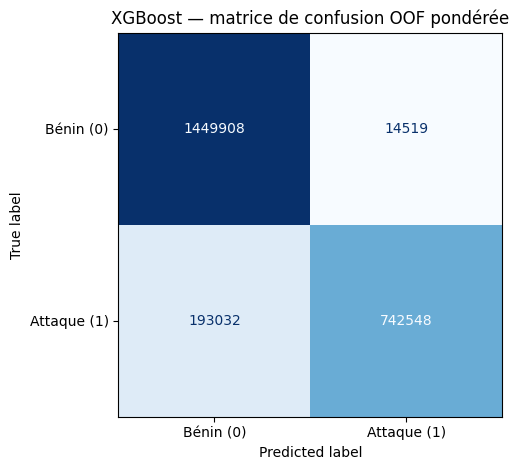

In [18]:
from sklearn.metrics import roc_curve, confusion_matrix ,ConfusionMatrixDisplay

def threshold_at_max_fpr(y_true, probability, weights, max_fpr=MAX_FPR):
    fpr, tpr, thresholds = roc_curve(
        y_true, probability, sample_weight=weights, drop_intermediate=False
    )
    eligible = np.flatnonzero(fpr <= max_fpr)
    if not len(eligible):
        return float(np.max(probability) + 1e-12)
    best = eligible[np.argmax(tpr[eligible])]
    return float(thresholds[best])

threshold = threshold_at_max_fpr(
    y_train, oof_probability, sampling_weight[train_idx], MAX_FPR
)
oof_prediction = (oof_probability >= threshold).astype(np.int8)
print("Seuil fixé sur les prédictions hors pli :", threshold)
oof_tn, oof_fp, oof_fn, oof_tp = confusion_matrix(
    y_train, oof_prediction, labels=[0, 1], sample_weight=sampling_weight[train_idx]
).ravel()
print("Rappel hors pli au seuil :", oof_tp / max(oof_tp + oof_fn, 1e-12))
print("FPR hors pli au seuil :", oof_fp / max(oof_fp + oof_tn, 1e-12))
print("FPR maximal imposé pour le choix du seuil :", f"{MAX_FPR:.1%}")





ConfusionMatrixDisplay.from_predictions(
    y_train, oof_prediction, labels=[0, 1],
    display_labels=["Bénin (0)", "Attaque (1)"],
    sample_weight=sampling_weight[train_idx], values_format=".0f",
    cmap="Blues", colorbar=False,
)
plt.title("XGBoost — matrice de confusion OOF pondérée")
plt.tight_layout()
plt.show()


### 5.2 Autres modèles — mêmes cinq plis stratifiés

Chaque modèle ci-dessous est entraîné dans sa propre cellule, en reprenant exactement les cinq plis `StratifiedKFold` du XGBoost et tout le train du même échantillon de 3 millions (environ 2,4 millions de lignes). Les poids, variables, plis et test restent communs. Les modèles sont ajustés séparément, sans boucle qui mélange les algorithmes. Les scores d’apprentissage et de validation sont calculés pli par pli; les prédictions hors pli servent à choisir le seuil. La cellule 6.3 rassemble ensuite les résultats et les matrices de confusion.


In [19]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

model_comparison_results = {}

def store_cv_model_result(name, model, preprocessor, train_score,
                          oof_model_score, test_model_score,
                          fold_rows, fit_seconds, loss_name):
    fold_table = pd.DataFrame(fold_rows)
    model_threshold = threshold_at_max_fpr(
        y_train, oof_model_score, sampling_weight[train_idx], MAX_FPR
    )
    model_comparison_results[name] = {
        "model": model,
        "preprocessor": preprocessor,
        "train_score": train_score,
        "oof_score": oof_model_score,
        "test_score": test_model_score,
        "threshold": model_threshold,
        "fold_results": fold_table,
        "fit_seconds": fit_seconds,
        "loss_name": loss_name,
    }
    display(fold_table.round(4))
    print(f"Seuil OOF {name} : {model_threshold:.5f}")
    print(f"Temps d’ajustement total : {fit_seconds:.1f} s")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(fold_table["pli"], fold_table["PR-AUC apprentissage"],
                 marker="o", label="Train")
    axes[0].plot(fold_table["pli"], fold_table["PR-AUC validation"],
                 marker="o", label="Validation")
    axes[0].set(xlabel="Pli StratifiedKFold", ylabel="PR-AUC pondérée",
                title=f"PR-AUC train / validation — {name}")
    axes[0].set_xticks(fold_table["pli"])
    axes[0].grid(alpha=0.25)
    axes[0].legend()
    axes[1].plot(fold_table["pli"], fold_table["perte apprentissage"],
                 marker="o", label="Train")
    axes[1].plot(fold_table["pli"], fold_table["perte validation"],
                 marker="o", label="Validation")
    axes[1].set(xlabel="Pli StratifiedKFold", ylabel=loss_name,
                title=f"Perte train / validation — {name}")
    axes[1].set_xticks(fold_table["pli"])
    axes[1].grid(alpha=0.25)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    oof_prediction_model = (oof_model_score >= model_threshold).astype(np.int8)
    ConfusionMatrixDisplay.from_predictions(
        y_train, oof_prediction_model, labels=[0, 1],
        display_labels=["Bénin (0)", "Attaque (1)"],
        sample_weight=sampling_weight[train_idx], values_format=".0f",
        cmap="Blues", colorbar=False,
    )
    plt.title(f"{name} — matrice de confusion OOF pondérée")
    plt.tight_layout()
    plt.show()


#### Modèle 1 — Régression logistique


Régression logistique — pli 1/5 terminé
Régression logistique — pli 2/5 terminé
Régression logistique — pli 3/5 terminé
Régression logistique — pli 4/5 terminé
Régression logistique — pli 5/5 terminé


,pli,PR-AUC apprentissage,PR-AUC validation,perte apprentissage,perte validation
0,1,0.9601,0.9597,0.3769,0.3795
1,2,0.9602,0.9602,0.3771,0.3781
2,3,0.9599,0.9602,0.3778,0.3770
3,4,0.9604,0.9601,0.3735,0.3752
4,5,0.9601,0.9605,0.3784,0.3747


Seuil OOF Régression logistique : 0.99993
Temps d’ajustement total : 74.8 s


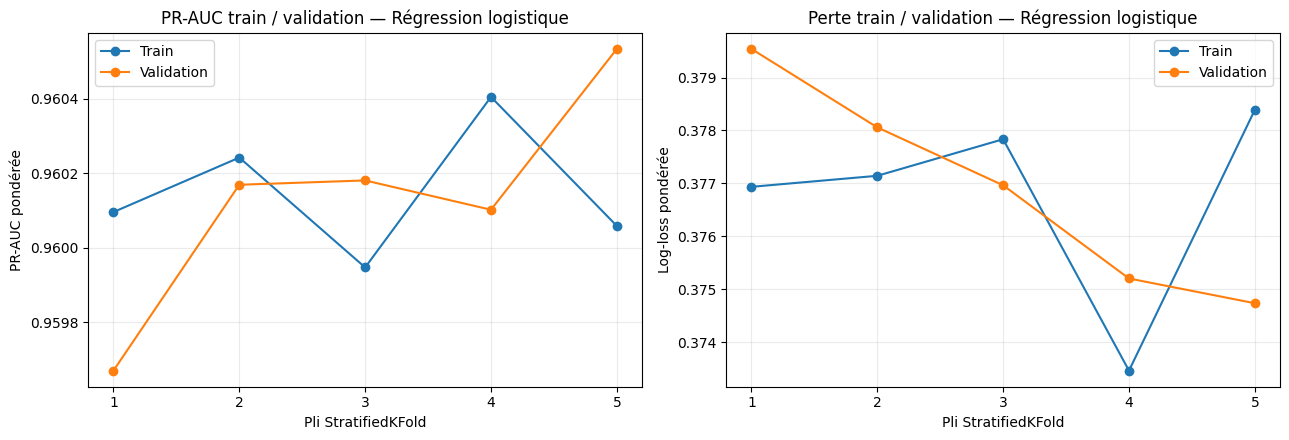

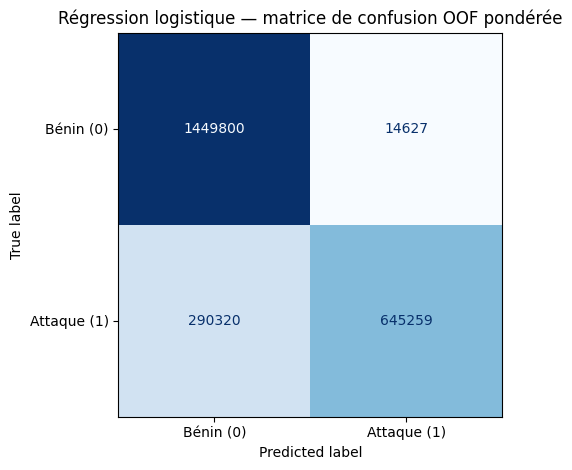

9056

In [20]:
# Régression logistique avec SGD : adaptée aux grandes matrices creuses.
logistic_oof_probability = np.full(len(train_idx), np.nan, dtype=np.float32)
logistic_train_probability = np.full(len(train_idx), np.nan, dtype=np.float32)
logistic_fold_rows = []
logistic_fit_seconds = 0.0

for fold, (fit_pos, valid_pos) in enumerate(
    cv.split(np.zeros(len(train_idx)), strata_train), start=1
):
    fit_idx = train_idx[fit_pos]
    valid_idx = train_idx[valid_pos]
    fold_prep = make_scaled_preprocessor()
    x_fit_fold = fold_prep.fit_transform(df_model.iloc[fit_idx][selected_features])
    x_valid_fold = fold_prep.transform(df_model.iloc[valid_idx][selected_features])
    logistic_fold = SGDClassifier(
        loss="log_loss", penalty="l2", alpha=best_params_by_model["Régression logistique"]["alpha"],
        max_iter=10, tol=None, average=True,
        random_state=RANDOM_STATE + fold, n_jobs=N_JOBS,
    )
    started = perf_counter()
    logistic_fold.fit(
        x_fit_fold, labels[fit_idx],
        sample_weight=balanced_training_weights(fit_idx),
    )
    logistic_fit_seconds += perf_counter() - started
    train_prob = logistic_fold.predict_proba(x_fit_fold)[:, 1]
    valid_prob = logistic_fold.predict_proba(x_valid_fold)[:, 1]
    logistic_train_probability[fit_pos] = train_prob
    logistic_oof_probability[valid_pos] = valid_prob
    logistic_fold_rows.append({
        "pli": fold,
        "PR-AUC apprentissage": average_precision_score(
            labels[fit_idx], train_prob, sample_weight=sampling_weight[fit_idx]
        ),
        "PR-AUC validation": average_precision_score(
            labels[valid_idx], valid_prob, sample_weight=sampling_weight[valid_idx]
        ),
        "perte apprentissage": log_loss(
            labels[fit_idx], train_prob, labels=[0, 1], sample_weight=sampling_weight[fit_idx]
        ),
        "perte validation": log_loss(
            labels[valid_idx], valid_prob, labels=[0, 1], sample_weight=sampling_weight[valid_idx]
        ),
    })
    print(f"Régression logistique — pli {fold}/{N_SPLITS} terminé")
    del x_fit_fold, x_valid_fold, train_prob, valid_prob, fold_prep, logistic_fold
    gc.collect()

# Ajustement final sur tout le train, puis une seule évaluation sur le test commun.
logistic_final_prep = make_scaled_preprocessor()
x_fit_final = logistic_final_prep.fit_transform(df_model.iloc[train_idx][selected_features])
x_test_final = logistic_final_prep.transform(df_model.iloc[test_idx][selected_features])
logistic_final = SGDClassifier(
    loss="log_loss", penalty="l2", alpha=1e-5,
    max_iter=10, tol=None, average=True,
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
)
started = perf_counter()
logistic_final.fit(
    x_fit_final, y_train, sample_weight=balanced_training_weights(train_idx)
)
logistic_fit_seconds += perf_counter() - started
logistic_test_probability = logistic_final.predict_proba(x_test_final)[:, 1]
store_cv_model_result(
    "Régression logistique", logistic_final, logistic_final_prep,
    logistic_train_probability, logistic_oof_probability,
    logistic_test_probability, logistic_fold_rows, logistic_fit_seconds,
    loss_name="Log-loss pondérée",
)
del x_fit_final, x_test_final, logistic_test_probability
gc.collect()


#### Modèle 2 — Arbre de décision


Arbre de décision — pli 1/5 terminé
Arbre de décision — pli 2/5 terminé
Arbre de décision — pli 3/5 terminé
Arbre de décision — pli 4/5 terminé
Arbre de décision — pli 5/5 terminé


,pli,PR-AUC apprentissage,PR-AUC validation,perte apprentissage,perte validation
0,1,0.9404,0.9402,0.1964,0.1968
1,2,0.9403,0.9400,0.1967,0.1972
2,3,0.9403,0.9399,0.1966,0.1977
3,4,0.9401,0.9402,0.1970,0.1969
4,5,0.9399,0.9406,0.1976,0.1964


Seuil OOF Arbre de décision : 0.97845
Temps d’ajustement total : 186.3 s


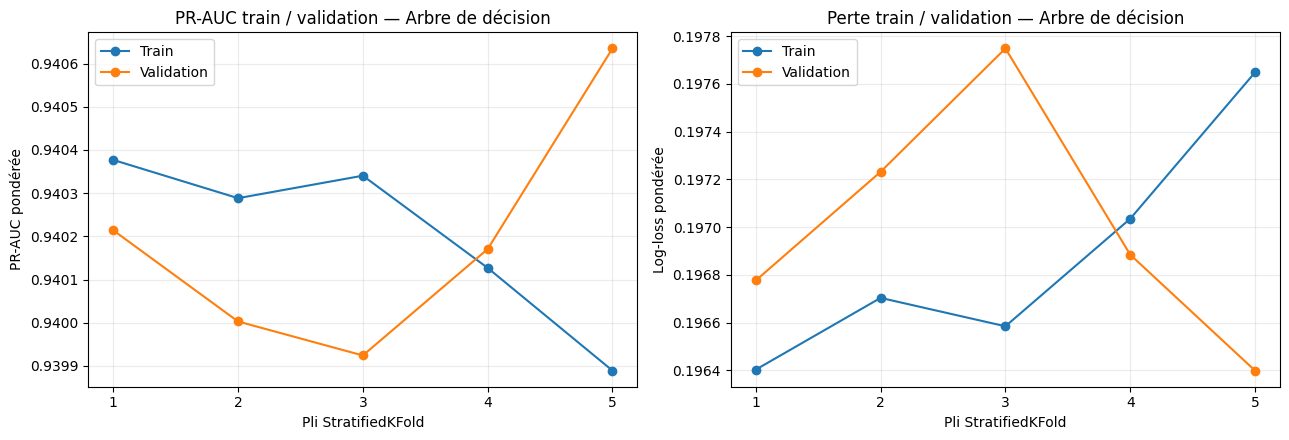

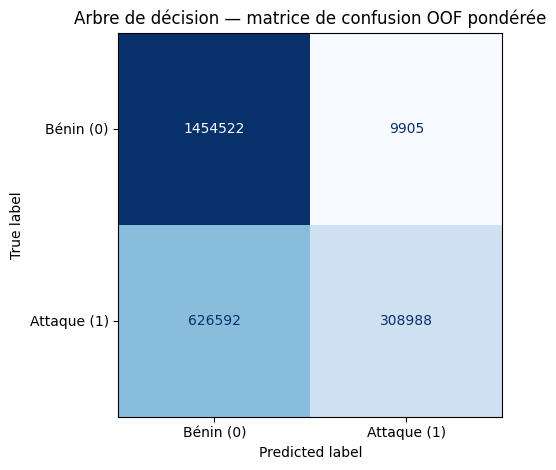

9696

In [21]:
# Arbre de décision de profondeur fixe pour garder un modèle simple et rapide.
tree_oof_probability = np.full(len(train_idx), np.nan, dtype=np.float32)
tree_train_probability = np.full(len(train_idx), np.nan, dtype=np.float32)
tree_fold_rows = []
tree_fit_seconds = 0.0

for fold, (fit_pos, valid_pos) in enumerate(
    cv.split(np.zeros(len(train_idx)), strata_train), start=1
):
    fit_idx = train_idx[fit_pos]
    valid_idx = train_idx[valid_pos]
    fold_prep = make_preprocessor()
    x_fit_fold = fold_prep.fit_transform(df_model.iloc[fit_idx][selected_features])
    x_valid_fold = fold_prep.transform(df_model.iloc[valid_idx][selected_features])
    tree_fold = DecisionTreeClassifier(
        max_depth=best_params_by_model["Arbre de décision"]["max_depth"],
        min_samples_leaf=best_params_by_model["Arbre de décision"]["min_samples_leaf"],
        random_state=RANDOM_STATE + fold
    )
    started = perf_counter()
    tree_fold.fit(
        x_fit_fold, labels[fit_idx],
        sample_weight=balanced_training_weights(fit_idx),
    )
    tree_fit_seconds += perf_counter() - started
    train_prob = tree_fold.predict_proba(x_fit_fold)[:, 1]
    valid_prob = tree_fold.predict_proba(x_valid_fold)[:, 1]
    tree_train_probability[fit_pos] = train_prob
    tree_oof_probability[valid_pos] = valid_prob
    tree_fold_rows.append({
        "pli": fold,
        "PR-AUC apprentissage": average_precision_score(
            labels[fit_idx], train_prob, sample_weight=sampling_weight[fit_idx]
        ),
        "PR-AUC validation": average_precision_score(
            labels[valid_idx], valid_prob, sample_weight=sampling_weight[valid_idx]
        ),
        "perte apprentissage": log_loss(
            labels[fit_idx], train_prob, labels=[0, 1], sample_weight=sampling_weight[fit_idx]
        ),
        "perte validation": log_loss(
            labels[valid_idx], valid_prob, labels=[0, 1], sample_weight=sampling_weight[valid_idx]
        ),
    })
    print(f"Arbre de décision — pli {fold}/{N_SPLITS} terminé")
    del x_fit_fold, x_valid_fold, train_prob, valid_prob, fold_prep, tree_fold
    gc.collect()

tree_final_prep = make_preprocessor()
x_fit_final = tree_final_prep.fit_transform(df_model.iloc[train_idx][selected_features])
x_test_final = tree_final_prep.transform(df_model.iloc[test_idx][selected_features])
tree_final = DecisionTreeClassifier(
    max_depth=best_params_by_model["Arbre de décision"]["max_depth"],
    min_samples_leaf=best_params_by_model["Arbre de décision"]["min_samples_leaf"],
    random_state=RANDOM_STATE
)
started = perf_counter()
tree_final.fit(
    x_fit_final, y_train, sample_weight=balanced_training_weights(train_idx)
)
tree_fit_seconds += perf_counter() - started
tree_test_probability = tree_final.predict_proba(x_test_final)[:, 1]
store_cv_model_result(
    "Arbre de décision", tree_final, tree_final_prep,
    tree_train_probability, tree_oof_probability,
    tree_test_probability, tree_fold_rows, tree_fit_seconds,
    loss_name="Log-loss pondérée",
)
del x_fit_final, x_test_final, tree_test_probability
gc.collect()


#### Modèle 3 — SVM linéaire (SGD)


SVM linéaire — pli 1/5 terminé
SVM linéaire — pli 2/5 terminé
SVM linéaire — pli 3/5 terminé
SVM linéaire — pli 4/5 terminé
SVM linéaire — pli 5/5 terminé


,pli,PR-AUC apprentissage,PR-AUC validation,perte apprentissage,perte validation
0,1,0.9568,0.9563,0.2210,0.2223
1,2,0.9566,0.9563,0.2214,0.2223
2,3,0.9560,0.9562,0.2216,0.2213
3,4,0.9561,0.9560,0.2217,0.2222
4,5,0.9563,0.9569,0.2236,0.2215


Seuil OOF SVM linéaire (SGD) : 3.18521
Temps d’ajustement total : 28.8 s


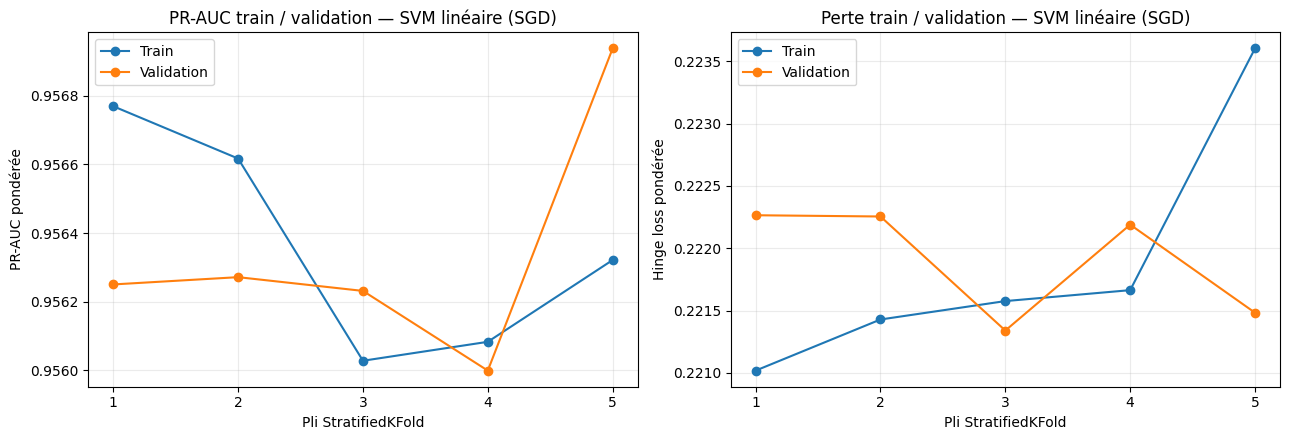

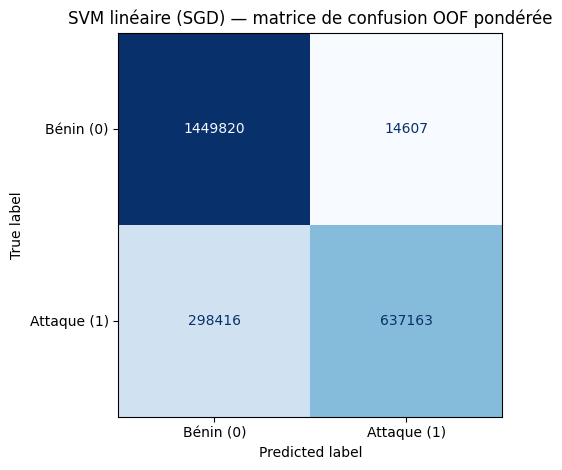

9146

In [22]:
# SVM linéaire entraîné par SGD : rapide et adapté aux matrices creuses.
# decision_function fournit un score; son seuil est calibré sur les prédictions hors pli.
svm_oof_score = np.full(len(train_idx), np.nan, dtype=np.float32)
svm_train_score = np.full(len(train_idx), np.nan, dtype=np.float32)
svm_fold_rows = []
svm_fit_seconds = 0.0

for fold, (fit_pos, valid_pos) in enumerate(
    cv.split(np.zeros(len(train_idx)), strata_train), start=1
):
    fit_idx = train_idx[fit_pos]
    valid_idx = train_idx[valid_pos]
    fold_prep = make_scaled_preprocessor()
    x_fit_fold = fold_prep.fit_transform(df_model.iloc[fit_idx][selected_features])
    x_valid_fold = fold_prep.transform(df_model.iloc[valid_idx][selected_features])
    svm_fold = SGDClassifier(
        loss="hinge", penalty="l2", alpha=best_params_by_model["SVM linéaire (SGD)"]["alpha"],
        max_iter=5, tol=None, average=True,
        random_state=RANDOM_STATE + fold, n_jobs=N_JOBS,
    )
    started = perf_counter()
    svm_fold.fit(
        x_fit_fold, labels[fit_idx],
        sample_weight=balanced_training_weights(fit_idx),
    )
    svm_fit_seconds += perf_counter() - started
    train_score = svm_fold.decision_function(x_fit_fold)
    valid_score = svm_fold.decision_function(x_valid_fold)
    svm_train_score[fit_pos] = train_score
    svm_oof_score[valid_pos] = valid_score
    svm_fold_rows.append({
        "pli": fold,
        "PR-AUC apprentissage": average_precision_score(
            labels[fit_idx], train_score, sample_weight=sampling_weight[fit_idx]
        ),
        "PR-AUC validation": average_precision_score(
            labels[valid_idx], valid_score, sample_weight=sampling_weight[valid_idx]
        ),
        "perte apprentissage": hinge_loss(
            labels[fit_idx], train_score, labels=[0, 1], sample_weight=sampling_weight[fit_idx]
        ),
        "perte validation": hinge_loss(
            labels[valid_idx], valid_score, labels=[0, 1], sample_weight=sampling_weight[valid_idx]
        ),
    })
    print(f"SVM linéaire — pli {fold}/{N_SPLITS} terminé")
    del x_fit_fold, x_valid_fold, train_score, valid_score, fold_prep, svm_fold
    gc.collect()

# Modèle final entraîné sur tout le train; le test reste réservé à l'évaluation.
svm_final_prep = make_scaled_preprocessor()
x_fit_final = svm_final_prep.fit_transform(df_model.iloc[train_idx][selected_features])
x_test_final = svm_final_prep.transform(df_model.iloc[test_idx][selected_features])
svm_final = SGDClassifier(
    loss="hinge", penalty="l2", alpha=1e-4,
    max_iter=5, tol=None, average=True,
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
)
started = perf_counter()
svm_final.fit(
    x_fit_final, y_train, sample_weight=balanced_training_weights(train_idx)
)
svm_fit_seconds += perf_counter() - started
svm_test_score = svm_final.decision_function(x_test_final)
store_cv_model_result(
    "SVM linéaire (SGD)", svm_final, svm_final_prep,
    svm_train_score, svm_oof_score, svm_test_score,
    svm_fold_rows, svm_fit_seconds,
    loss_name="Hinge loss pondérée",
)
del x_fit_final, x_test_final, svm_test_score
gc.collect()


### 5.3 Choix du meilleur modèle binaire

Le classement suit le besoin métier : rappel pondéré maximal parmi les modèles dont le FPR OOF respecte la limite de 1 %. La PR-AUC départage les modèles ayant le même rappel. Les prédictions proviennent des cinq validations hors pli ; le test n’intervient pas dans ce choix.


,modèle,rappel OOF pondéré,FPR OOF pondéré,PR-AUC OOF pondérée,seuil OOF,FPR admissible
0,XGBoost,0.79368,0.00991,0.97456,0.95115,True
1,Régression logistique,0.68969,0.00999,0.96204,0.99993,True
3,SVM linéaire (SGD),0.68104,0.00997,0.95787,3.18521,True
2,Arbre de décision,0.33026,0.00676,0.94677,0.97845,True


Meilleur modèle binaire retenu : XGBoost
Rappel OOF : 0.7937 | FPR OOF : 0.9914% | seuil : 0.95115


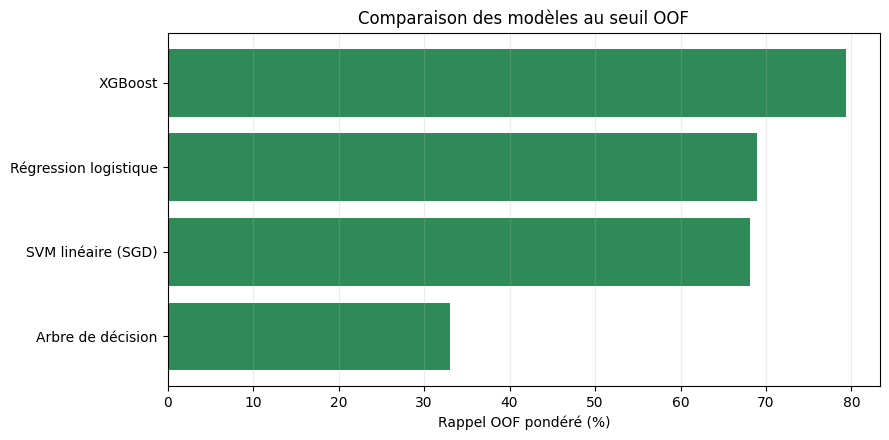

In [23]:
def summarize_binary_oof(name, score, threshold_value, pr_auc):
    prediction = (score >= threshold_value).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(
        y_train, prediction, labels=[0, 1], sample_weight=sampling_weight[train_idx]
    ).ravel()
    return {
        "modèle": name,
        "rappel OOF pondéré": tp / max(tp + fn, 1e-12),
        "FPR OOF pondéré": fp / max(fp + tn, 1e-12),
        "PR-AUC OOF pondérée": pr_auc,
        "seuil OOF": threshold_value,
    }

selection_rows = [summarize_binary_oof(
    "XGBoost", oof_probability, threshold,
    average_precision_score(y_train, oof_probability, sample_weight=sampling_weight[train_idx]),
)]
for model_name, result in model_comparison_results.items():
    selection_rows.append(summarize_binary_oof(
        model_name, result["oof_score"], result["threshold"],
        average_precision_score(y_train, result["oof_score"], sample_weight=sampling_weight[train_idx]),
    ))
model_selection_table = pd.DataFrame(selection_rows)
model_selection_table["FPR admissible"] = model_selection_table["FPR OOF pondéré"] <= MAX_FPR + 1e-12
display(model_selection_table.sort_values(
    ["FPR admissible", "rappel OOF pondéré", "PR-AUC OOF pondérée"],
    ascending=[False, False, False]
).round(5))

eligible_models = model_selection_table[model_selection_table["FPR admissible"]]
if eligible_models.empty:
    eligible_models = model_selection_table
best_model_row = eligible_models.sort_values(
    ["rappel OOF pondéré", "PR-AUC OOF pondérée"], ascending=False
).iloc[0]
best_model_name = best_model_row["modèle"]
best_model_threshold = float(best_model_row["seuil OOF"])
best_binary_result = model_comparison_results.get(best_model_name)
print(f"Meilleur modèle binaire retenu : {best_model_name}")
print(f"Rappel OOF : {best_model_row['rappel OOF pondéré']:.4f} | "
      f"FPR OOF : {best_model_row['FPR OOF pondéré']:.4%} | "
      f"seuil : {best_model_threshold:.5f}")

plot_selection = model_selection_table.sort_values("rappel OOF pondéré", ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["seagreen" if ok else "lightgray" for ok in plot_selection["FPR admissible"]]
ax.barh(plot_selection["modèle"], 100 * plot_selection["rappel OOF pondéré"], color=colors)
ax.set(xlabel="Rappel OOF pondéré (%)", title="Comparaison des modèles au seuil OOF")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 6. CRISP-DM — Evaluation : test tenu à l’écart

Le modèle est choisi exclusivement avec les prédictions OOF du train. Le modèle retenu est ajusté sur tout le train, puis évalué une seule fois sur le test avec son seuil OOF figé. Les scores continus du SVM sont utilisés comme scores de classement pour les courbes PR/ROC.


In [24]:
from sklearn.metrics import (
    balanced_accuracy_score, confusion_matrix, f1_score,
    matthews_corrcoef, precision_score, recall_score,
    average_precision_score, roc_auc_score, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, accuracy_score, classification_report,
)

if best_model_name == "XGBoost":
    final_preprocessor = make_preprocessor()
    x_train_raw = df_model.iloc[train_idx][selected_features]
    x_test_raw = df_model.iloc[test_idx][selected_features]
    x_train = final_preprocessor.fit_transform(x_train_raw)
    x_test = final_preprocessor.transform(x_test_raw)
    final_model = make_model(
        labels[train_idx], sampling_weight[train_idx],
        model_params=best_params_by_model["XGBoost"],
    )
    final_fit_started = perf_counter()
    final_model.fit(
        x_train, labels[train_idx], sample_weight=sampling_weight[train_idx], verbose=False
    )
    final_fit_seconds = perf_counter() - final_fit_started
    test_score = final_model.predict_proba(x_test)[:, 1]
    final_score_method = "predict_proba[:, 1]"
else:
    final_model = best_binary_result["model"]
    final_preprocessor = best_binary_result["preprocessor"]
    final_fit_seconds = best_binary_result["fit_seconds"]
    test_score = best_binary_result["test_score"]
    final_score_method = (
        "decision_function" if best_model_name.startswith("SVM") else "predict_proba[:, 1]"
    )

final_threshold = best_model_threshold
test_prediction = (test_score >= final_threshold).astype(np.int8)
test_weights = sampling_weight[test_idx]
tn, fp, fn, tp = confusion_matrix(
    labels[test_idx], test_prediction, labels=[0, 1], sample_weight=test_weights
).ravel()
test_fpr = fp / max(fp + tn, 1e-12)
test_metrics = {
    "modèle retenu": best_model_name,
    "PR-AUC": average_precision_score(labels[test_idx], test_score, sample_weight=test_weights),
    "ROC-AUC": roc_auc_score(labels[test_idx], test_score, sample_weight=test_weights),
    "rappel attaque": recall_score(labels[test_idx], test_prediction, sample_weight=test_weights, zero_division=0),
    "précision attaque": precision_score(labels[test_idx], test_prediction, sample_weight=test_weights, zero_division=0),
    "F1": f1_score(labels[test_idx], test_prediction, sample_weight=test_weights, zero_division=0),
    "MCC (non pondéré)": matthews_corrcoef(labels[test_idx], test_prediction),
    "balanced accuracy": balanced_accuracy_score(labels[test_idx], test_prediction, sample_weight=test_weights),
    "FPR": test_fpr,
    "seuil fixé sur OOF": final_threshold,
    "FPR ≤ 1 % respecté sur test": bool(test_fpr <= MAX_FPR),
    "TN pondérés": tn, "FP pondérés": fp,
    "FN pondérés": fn, "TP pondérés": tp,
    "temps d’ajustement du modèle final (s)": final_fit_seconds,
}
display(pd.Series(test_metrics, name="test").to_frame())


,test
modèle retenu,XGBoost
PR-AUC,0.972981
ROC-AUC,0.982351
rappel attaque,0.733443
précision attaque,0.983308
F1,0.840192
MCC (non pondéré),0.779159
balanced accuracy,0.862745
FPR,0.007954
seuil fixé sur OOF,0.951153


### 6.1 Visualisations d’évaluation et rappel par attaque

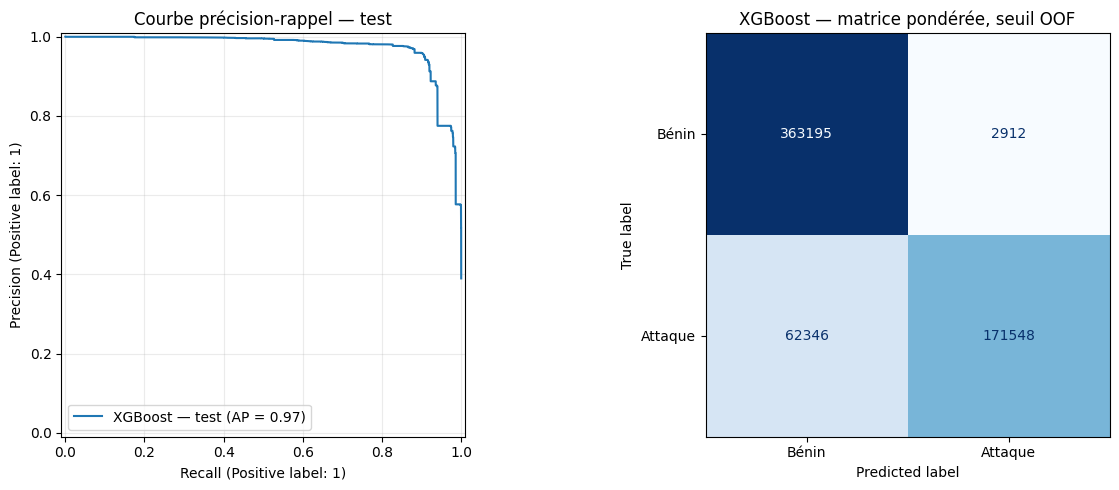

,Attack,attaques test (échantillon),attaques estimées (pondérées),rappel binaire
1,ddos,90288,90288.179688,0.953504
8,xss,61797,61797.242188,0.707963
5,password,34770,34770.003906,0.899942
7,scanning,29628,29628.050781,0.000169
3,injection,8323,8322.968750,0.746606
2,dos,4436,4435.982422,0.004058
0,Backdoor,4434,4434.012695,0.940235
4,mitm,131,131.096466,0.076336
6,ransomware,87,86.976303,0.011494


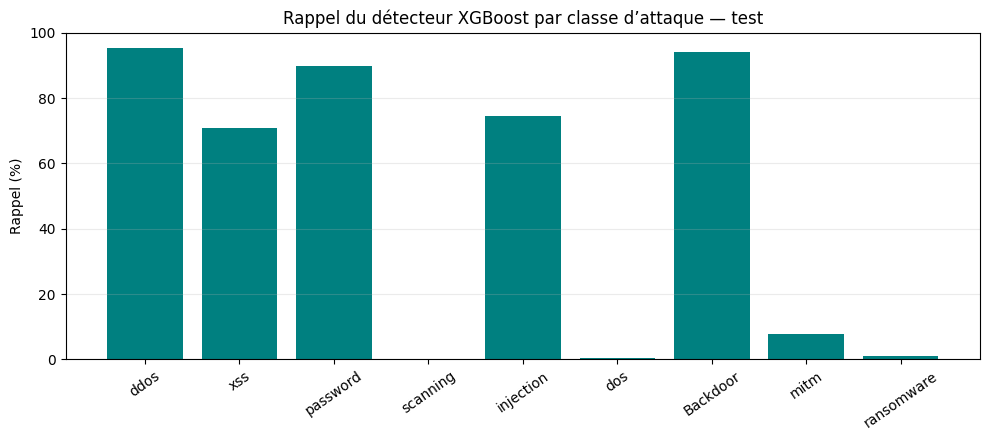

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
PrecisionRecallDisplay.from_predictions(
    labels[test_idx], test_score,
    sample_weight=test_weights, name=f"{best_model_name} — test", ax=axes[0]
)
axes[0].set_title("Courbe précision-rappel — test")
axes[0].grid(alpha=0.25)
ConfusionMatrixDisplay.from_predictions(
    labels[test_idx], test_prediction, labels=[0, 1],
    display_labels=["Bénin", "Attaque"], sample_weight=test_weights,
    values_format=".0f", cmap="Blues", colorbar=False, ax=axes[1]
)
axes[1].set_title(f"{best_model_name} — matrice pondérée, seuil OOF")
plt.tight_layout()
plt.show()

attack_recall_rows = []
for attack_code, attack in enumerate(attack_levels):
    mask = (attack_codes[test_idx] == attack_code) & (labels[test_idx] == 1)
    if mask.any():
        attack_recall_rows.append({
            "Attack": attack,
            "attaques test (échantillon)": int(mask.sum()),
            "attaques estimées (pondérées)": float(test_weights[mask].sum()),
            "rappel binaire": float(np.average(test_prediction[mask], weights=test_weights[mask]))
        })
attack_recall = pd.DataFrame(attack_recall_rows).sort_values(
    "attaques estimées (pondérées)", ascending=False
)
display(attack_recall)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(attack_recall["Attack"], 100 * attack_recall["rappel binaire"], color="teal")
ax.set_ylabel("Rappel (%)")
ax.set_title(f"Rappel du détecteur {best_model_name} par classe d’attaque — test")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 6.2 Classification multiclasses des types d’attaque

Après avoir sélectionné le modèle binaire, le même algorithme et les mêmes hyperparamètres sont réentraînés sur les seules lignes d’attaque (`Label = 1`). La cible devient `Attack`. Le test ne contient que les attaques pour cette étape ; les matrices de confusion, le rapport de classification et les courbes précision-rappel sont calculés par type.


,test multiclasses
modèle réutilisé,XGBoost
classes d’attaque,9
accuracy pondérée,0.963796
F1 macro pondéré,0.859571
lignes attaque train,935577
lignes attaque test,233894
temps d’ajustement (s),37.148652


              precision    recall  f1-score   support

    Backdoor       1.00      1.00      1.00 4434.013214349747
        ddos       0.99      0.99      0.99 90288.1829738617
         dos       0.45      0.95      0.61 4435.9828135967255
   injection       0.82      0.91      0.87 8322.968746364117
        mitm       0.24      0.98      0.39 131.09647822380066
    password       0.99      0.99      0.99 34770.008289813995
  ransomware       0.91      0.99      0.95 86.97632253170013
    scanning       1.00      1.00      1.00 29628.052978992462
         xss       0.99      0.90      0.94 61797.24310362339

    accuracy                           0.96 233894.52492135763
   macro avg       0.82      0.97      0.86 233894.52492135763
weighted avg       0.98      0.96      0.97 233894.52492135763



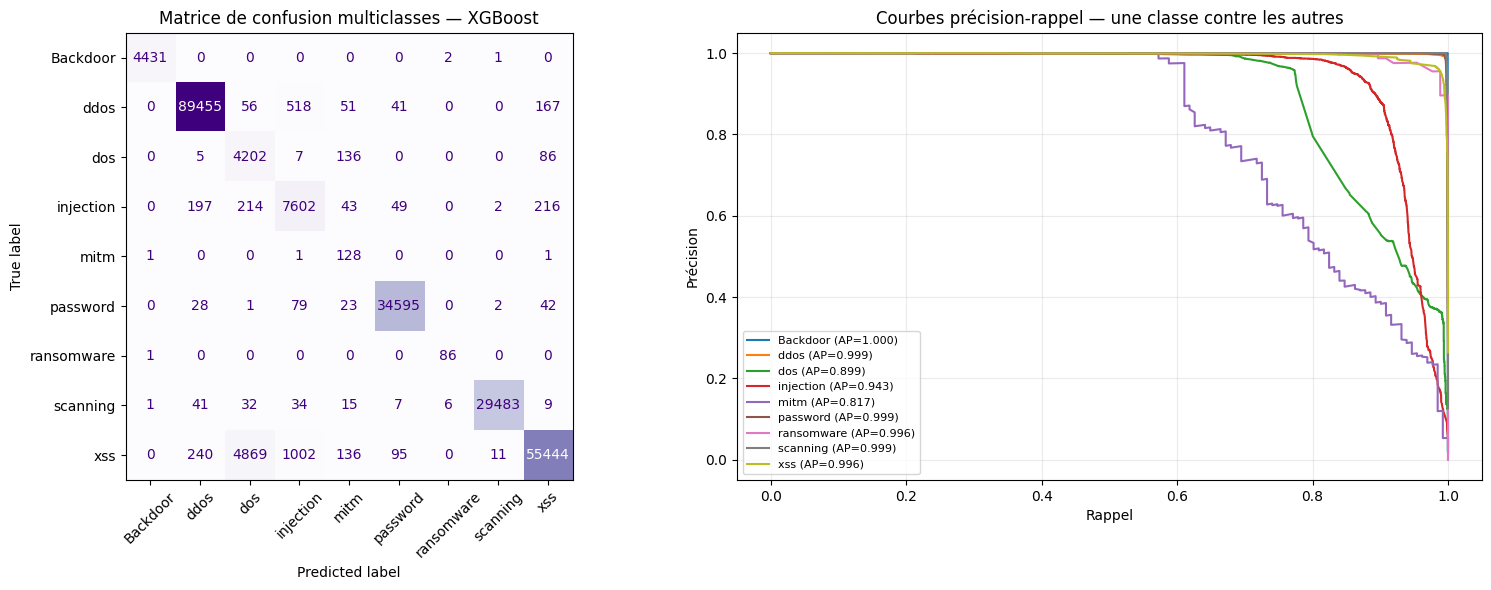

In [26]:
from sklearn.metrics import precision_recall_curve, average_precision_score, f1_score, accuracy_score

attack_names = [name for name in attack_levels if name != "Benign"]
attack_name_to_class = {name: class_id for class_id, name in enumerate(attack_names)}
code_to_multiclass = np.full(len(attack_levels), -1, dtype=np.int16)
for attack_code, attack_name in enumerate(attack_levels):
    if attack_name in attack_name_to_class:
        code_to_multiclass[attack_code] = attack_name_to_class[attack_name]
multiclass_target = code_to_multiclass[attack_codes]
attack_train_idx = train_idx[labels[train_idx] == 1]
attack_test_idx = test_idx[labels[test_idx] == 1]
y_attack_train = multiclass_target[attack_train_idx]
y_attack_test = multiclass_target[attack_test_idx]
multiclass_names = attack_names
n_attack_classes = len(multiclass_names)
if n_attack_classes < 2:
    raise ValueError("Il faut au moins deux classes d’attaque pour l’étape multiclasses.")

multiclass_preprocessor = (
    make_scaled_preprocessor() if best_model_name in {"Régression logistique", "SVM linéaire (SGD)"}
    else make_preprocessor()
)
x_attack_train = multiclass_preprocessor.fit_transform(
    df_model.iloc[attack_train_idx][selected_features]
)
x_attack_test = multiclass_preprocessor.transform(
    df_model.iloc[attack_test_idx][selected_features]
)

attack_class_weights = np.bincount(
    y_attack_train, weights=sampling_weight[attack_train_idx], minlength=n_attack_classes
)
class_weight_factors = attack_class_weights.mean() / np.maximum(attack_class_weights, 1e-12)
attack_train_weights = sampling_weight[attack_train_idx] * class_weight_factors[y_attack_train]

if best_model_name == "XGBoost":
    xgb_params = best_params_by_model["XGBoost"].copy()
    multiclass_model = XGBClassifier(
        n_estimators=xgb_params.get("n_estimators", N_ESTIMATORS),
        max_depth=xgb_params.get("max_depth", MAX_DEPTH),
        learning_rate=xgb_params.get("learning_rate", 0.06),
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=5.0,
        objective="multi:softprob", num_class=n_attack_classes, eval_metric="mlogloss",
        tree_method="hist", n_jobs=N_JOBS, random_state=RANDOM_STATE,
    )
elif best_model_name == "Arbre de décision":
    multiclass_model = DecisionTreeClassifier(
        **best_params_by_model[best_model_name], random_state=RANDOM_STATE
    )
else:
    multiclass_model = SGDClassifier(
        loss="log_loss" if best_model_name == "Régression logistique" else "hinge",
        penalty="l2", alpha=best_params_by_model[best_model_name]["alpha"],
        max_iter=10 if best_model_name == "Régression logistique" else 5,
        tol=None, average=True, random_state=RANDOM_STATE, n_jobs=N_JOBS,
    )

multiclass_started = perf_counter()
multiclass_model.fit(
    x_attack_train, y_attack_train, sample_weight=attack_train_weights
)
multiclass_fit_seconds = perf_counter() - multiclass_started
multiclass_prediction = multiclass_model.predict(x_attack_test)
if hasattr(multiclass_model, "predict_proba"):
    multiclass_scores = multiclass_model.predict_proba(x_attack_test)
else:
    multiclass_scores = multiclass_model.decision_function(x_attack_test)
    if multiclass_scores.ndim == 1:
        multiclass_scores = np.column_stack([-multiclass_scores, multiclass_scores])

multiclass_weights = sampling_weight[attack_test_idx]
multiclass_metrics = {
    "modèle réutilisé": best_model_name,
    "classes d’attaque": n_attack_classes,
    "accuracy pondérée": accuracy_score(
        y_attack_test, multiclass_prediction, sample_weight=multiclass_weights
    ),
    "F1 macro pondéré": f1_score(
        y_attack_test, multiclass_prediction, average="macro",
        sample_weight=multiclass_weights, zero_division=0,
    ),
    "lignes attaque train": len(attack_train_idx),
    "lignes attaque test": len(attack_test_idx),
    "temps d’ajustement (s)": multiclass_fit_seconds,
}
display(pd.Series(multiclass_metrics, name="test multiclasses").to_frame())
print(classification_report(
    y_attack_test, multiclass_prediction, labels=np.arange(n_attack_classes),
    target_names=multiclass_names, sample_weight=multiclass_weights,
    zero_division=0, output_dict=False,
))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay.from_predictions(
    y_attack_test, multiclass_prediction, labels=np.arange(n_attack_classes),
    display_labels=multiclass_names, sample_weight=multiclass_weights,
    values_format=".0f", cmap="Purples", colorbar=False, ax=axes[0], xticks_rotation=45,
)
axes[0].set_title(f"Matrice de confusion multiclasses — {best_model_name}")
for class_id, attack_name in enumerate(multiclass_names):
    binary_truth = (y_attack_test == class_id).astype(np.int8)
    if binary_truth.min() == binary_truth.max():
        continue
    precision, recall, _ = precision_recall_curve(
        binary_truth, multiclass_scores[:, class_id], sample_weight=multiclass_weights
    )
    class_ap = average_precision_score(
        binary_truth, multiclass_scores[:, class_id], sample_weight=multiclass_weights
    )
    axes[1].plot(recall, precision, label=f"{attack_name} (AP={class_ap:.3f})")
axes[1].set(xlabel="Rappel", ylabel="Précision", title="Courbes précision-rappel — une classe contre les autres")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


### 6.2 Importance des caractéristiques

,variable encodée,importance
2,mesures__OUT_BYTES,0.178798
96,codes__L4_DST_PORT_infrequent_sklearn,0.123094
23,mesures__TCP_WIN_MAX_IN,0.054930
99,codes__PROTOCOL_6.0,0.050560
9,mesures__MIN_IP_PKT_LEN,0.050360
275,codes__DNS_QUERY_TYPE_1.0,0.042423
39,codes__L4_DST_PORT_53.0,0.041181
187,codes__CLIENT_TCP_FLAGS_0.0,0.039381
50,codes__L4_DST_PORT_443.0,0.038525
191,codes__CLIENT_TCP_FLAGS_16.0,0.028360


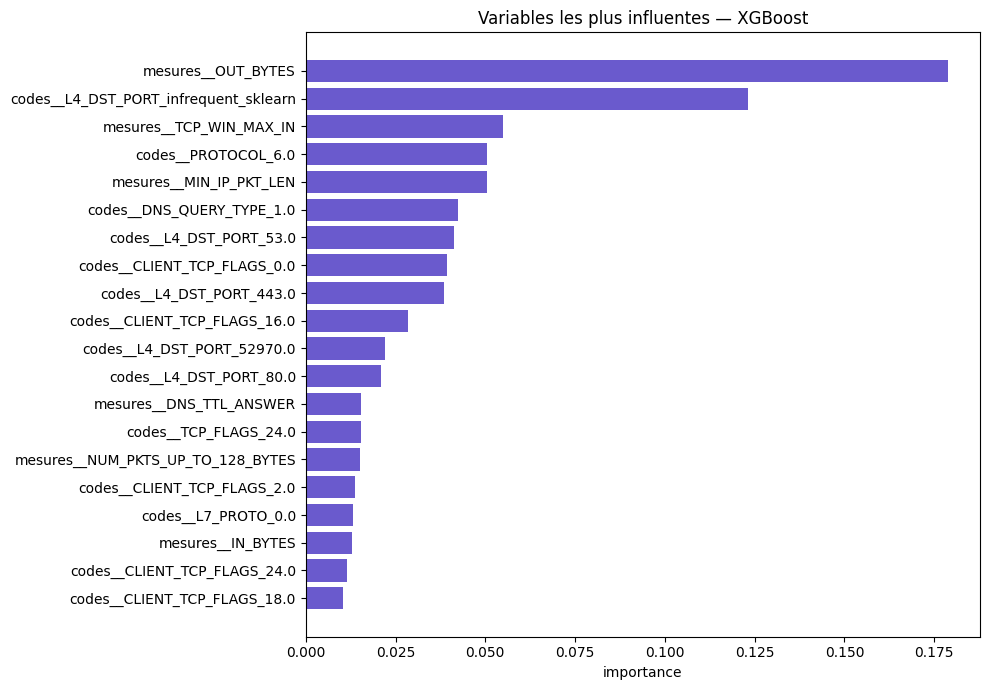

In [27]:
feature_names_encoded = final_preprocessor.get_feature_names_out()
if hasattr(final_model, "feature_importances_"):
    importance_values = final_model.feature_importances_
    importance_label = "importance"
elif hasattr(final_model, "coef_"):
    importance_values = np.mean(np.abs(final_model.coef_), axis=0)
    importance_label = "coefficient absolu moyen"
else:
    importance_values = np.zeros(len(feature_names_encoded))
    importance_label = "importance"
importance = pd.DataFrame({
    "variable encodée": feature_names_encoded,
    importance_label: importance_values,
}).sort_values(importance_label, ascending=False)
display(importance.head(25))
plot_importance = importance.head(20).sort_values(importance_label)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_importance["variable encodée"], plot_importance[importance_label], color="slateblue")
ax.set_xlabel(importance_label)
ax.set_title(f"Variables les plus influentes — {best_model_name}")
plt.tight_layout()
plt.show()


## 7. CRISP-DM Deployment : enregistrer les modèles retenus

La dernière cellule exporte le meilleur détecteur binaire choisi sur OOF, son seuil et le classifieur multiclasses des types d’attaque, avec leurs prétraitements et métadonnées.


In [28]:
import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "nids_modele_selectionne_3m.joblib"

model_bundle = {
    "best_binary_model": {
        "name": best_model_name,
        "classifier": final_model,
        "preprocessor": final_preprocessor,
        "threshold": float(final_threshold),
        "score_method": final_score_method,
    },
    "multiclass_attack_model": {
        "classifier": multiclass_model,
        "preprocessor": multiclass_preprocessor,
        "classes": multiclass_names,
        "target": "Attack parmi les lignes Label = 1",
    },
    "features": selected_features,
    "categorical_features": categorical_features,
    "max_validation_fpr": MAX_FPR,
    "best_binary_oof_metrics": best_model_row.to_dict(),
    "random_state": RANDOM_STATE,
    "sample_file": SAMPLE_NAME,
    "sample_manifest": MANIFEST_NAME,
}
joblib.dump(model_bundle, MODEL_PATH)
print("Modèle binaire retenu :", best_model_name)
print("Classifieur multiclasses :", n_attack_classes, "types d’attaque")
print("Artefact sauvegardé :", MODEL_PATH)


Modèle binaire retenu : XGBoost
Classifieur multiclasses : 9 types d’attaque
Artefact sauvegardé : /Users/a/Desktop/Projet_DATAMINING-NIDS/models/nids_modele_selectionne_3m.joblib
